# RADIOMIC FEATURES EXTRACTION (2D+3D)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import SimpleITK as sitk
from radiomics import featureextractor


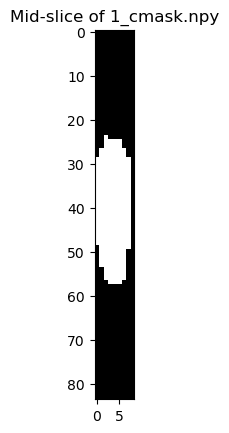

In [24]:
mask = np.load("C:/Users/user/Desktop/PI_project/deeplung_features/1_cmask.npy")
plt.imshow(mask[mask.shape[0]//2], cmap="gray")  # Show central slice
plt.title("Mid-slice of 1_cmask.npy")
plt.show()


In [173]:
print(f"Mask shape: {cmask.shape}")
print(f"Image shape: {image_array.shape}")


Mask shape: (62, 62, 4)
Image shape: (512, 512)


# 2D RADIOMIC features extraction

In [181]:
# Define paths
input_directory = "C:/Users/user/Desktop/PI_project/images/LIDC-IDRI"
params_file = "C:/Users/user/Desktop/PI_project/radiomics_config/Params.yaml"
path = "C:/Users/user/Desktop/PI_project/deeplung_features"
output= "C:/Users/user/Desktop/PI_project/radiomics_output"
# Create feature extractor using the setup file
extractor = featureextractor.RadiomicsFeatureExtractor(params_file)

# List to store feature dictionaries
dic_list = []

# Get list of all .npy files in the directory
archives_npy = [archive for archive in os.listdir(path) if archive.endswith('cmask.npy')]

# Order the archives by the nodule ID (assuming it's the first part of the filename)
ordered_archives = sorted(archives_npy, key=lambda x: int(x.split('_')[0]))

# Loop through each archive, load the mask, and extract features
for archive in ordered_archives:
    # Load the consensus mask (2D)
    cmask = np.load(os.path.join(path, archive))
    
    # Check if the mask is non-empty and has the expected shape
    if cmask.size == 0:
        print(f"⚠️ Empty mask: {archive}")
        continue  # Skip empty masks
    
    print(f"Processing: {archive}, Mask Shape: {cmask.shape}")
    
    # Convert to SimpleITK Image
    image = sitk.GetImageFromArray(cmask.astype(float))
    
    try:
        # Extract radiomics features (using the mask itself as both image and mask)
        features = extractor.execute(image, image, label=1)
        
        # Check if features were extracted
        if len(features) == 0:
            print(f"⚠️ No features extracted for: {archive}")
            continue
        
        # Append features to the dictionary list
        dic_list.append(features)
        
        # Extract the nodule ID from the filename and add it to the features
        nodule_id = int(archive.split('_')[0])
        features['Nodule_id'] = nodule_id
        print(f"Successfully extracted features for: {archive}")

    except Exception as e:
        print(f"Error processing {archive}: {e}")

# If any features were successfully extracted, save to CSV
if dic_list:
    features_df = pd.DataFrame(dic_list)
    csv_filename = os.path.join(output, 'features_radiomics_2d.csv')
    features_df.to_csv(csv_filename, index=False)
    print(f"Features saved to {csv_filename}")
else:
    print("No features were extracted. CSV not saved.")


Processing: 1_cmask.npy, Mask Shape: (92, 84, 9)
Successfully extracted features for: 1_cmask.npy
Processing: 2_cmask.npy, Mask Shape: (85, 90, 28)
Successfully extracted features for: 2_cmask.npy
Processing: 3_cmask.npy, Mask Shape: (76, 74, 8)
Successfully extracted features for: 3_cmask.npy
Processing: 4_cmask.npy, Mask Shape: (80, 85, 10)
Successfully extracted features for: 4_cmask.npy
Processing: 5_cmask.npy, Mask Shape: (60, 59, 8)
Successfully extracted features for: 5_cmask.npy
Processing: 6_cmask.npy, Mask Shape: (51, 51, 5)
Successfully extracted features for: 6_cmask.npy
Processing: 7_cmask.npy, Mask Shape: (49, 51, 2)
Successfully extracted features for: 7_cmask.npy
Processing: 8_cmask.npy, Mask Shape: (51, 51, 2)
Successfully extracted features for: 8_cmask.npy
Processing: 9_cmask.npy, Mask Shape: (62, 62, 4)
Successfully extracted features for: 9_cmask.npy
Processing: 10_cmask.npy, Mask Shape: (93, 85, 13)
Successfully extracted features for: 10_cmask.npy
Processing: 11_

# 3D RADIOMIC features extraction

JUST GO FROM HERE

In [190]:
import numpy as np

# Example for nodule 1
mask_path = r"C:\Users\user\Desktop\PI_project\deeplung_features\1_cmask.npy"
mask = np.load(mask_path)

print(f"Mask shape: {mask.shape}")


Mask shape: (92, 84, 9)



🔍 Mask filename: 1_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\1_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0001\01-01-2000-NA-NA-30178\3000566.000000-NA-03192


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 1


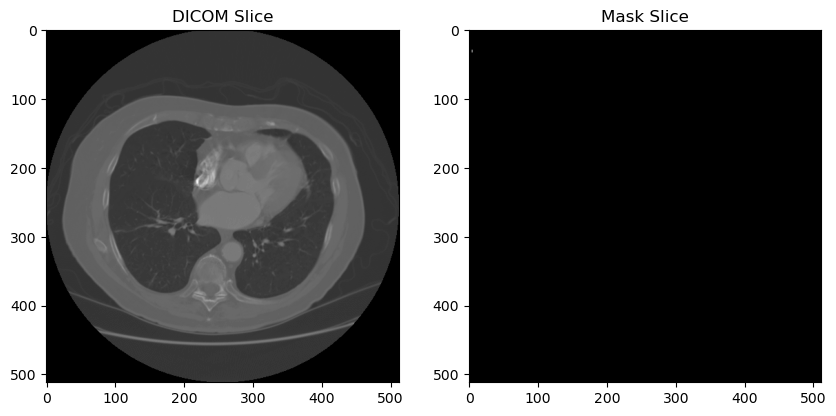

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0001\01-01-2000-NA-NA-35511\3000923.000000-NA-62357
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 2_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\2_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0002\01-01-2000-NA-NA-26851\3000972.000000-NA-22902
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0002\01-01-2000-NA-NA-98329\3000522.000000-NA-04919


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 2


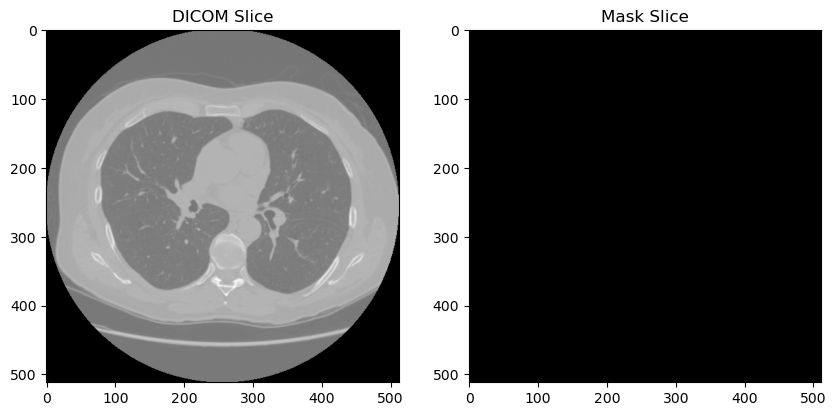


🔍 Mask filename: 3_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\3_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0003\01-01-2000-NA-NA-59141\3000978.000000-NA-59882
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0003\01-01-2000-NA-NA-59141\3000978.000000-NA-59882 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0003\01-01-2000-NA-NA-94866\3000611.000000-NA-03264


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 3


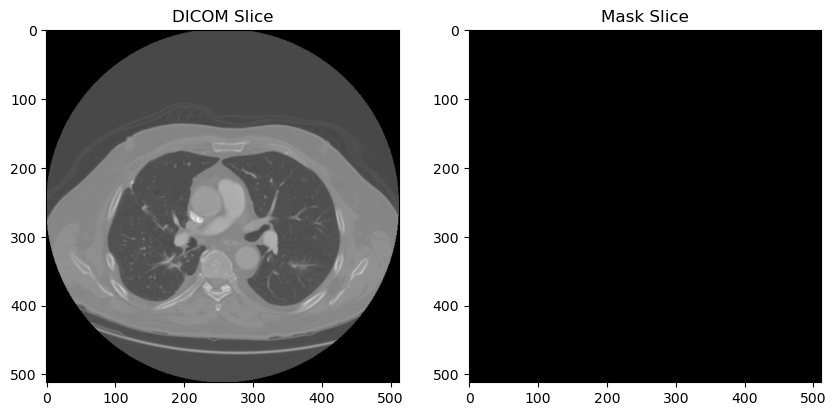


🔍 Mask filename: 4_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\4_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0004\01-01-2000-NA-NA-88534\3000897.000000-NA-82201
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0004\01-01-2000-NA-NA-91780\3000534.000000-NA-58228


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 4


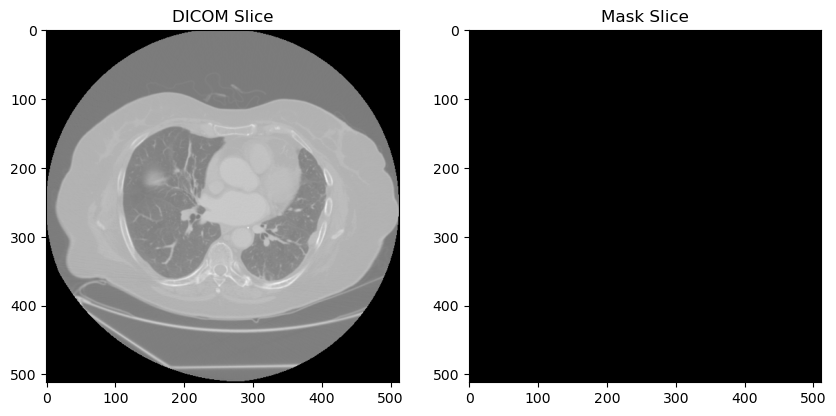


🔍 Mask filename: 5_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\5_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0005\01-01-2000-NA-NA-06608\3001613.000000-NA-05796
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0005\01-01-2000-NA-NA-42125\3000548.000000-NA-86225


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 5


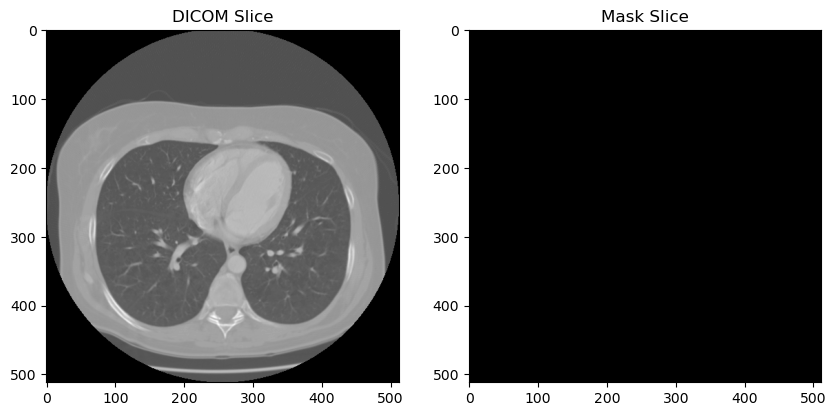


🔍 Mask filename: 6_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\6_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0006\01-01-2000-NA-NA-15339\3000974.000000-NA-44874
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0006\01-01-2000-NA-NA-92500\3000556.000000-NA-20957


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 6


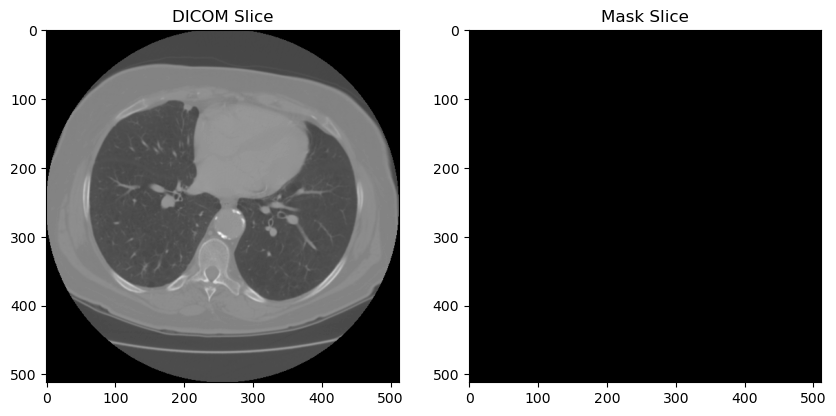


🔍 Mask filename: 7_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\7_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0007\01-01-2000-NA-NA-08604\3000981.000000-NA-87749
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0007\01-01-2000-NA-NA-81781\3000631.000000-NA-57680


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 7


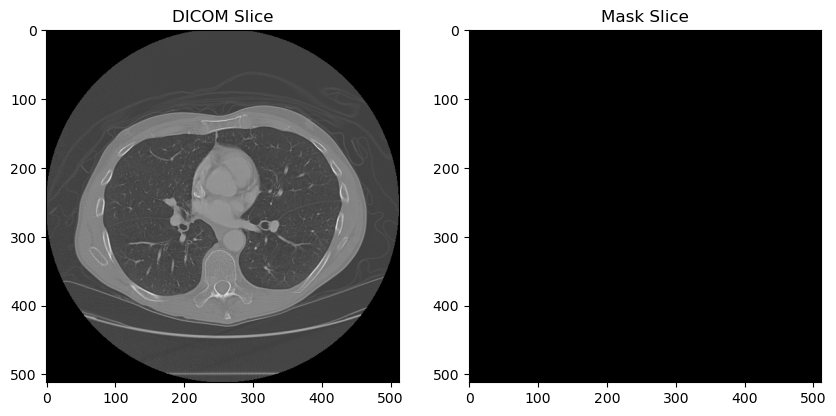


🔍 Mask filename: 8_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\8_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0008\01-01-2000-NA-NA-30141\3000549.000000-NA-21954


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 8


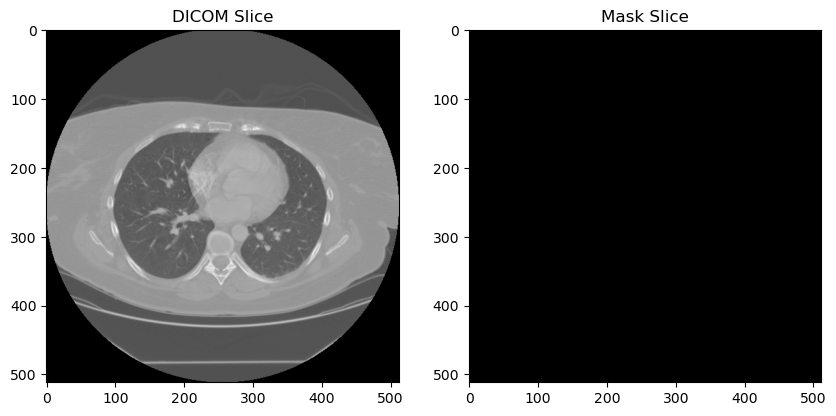

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0008\01-01-2000-NA-NA-46755\3001591.000000-NA-37639
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 9_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\9_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0009\01-01-2000-NA-NA-07045\3000538.000000-NA-29210


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 9


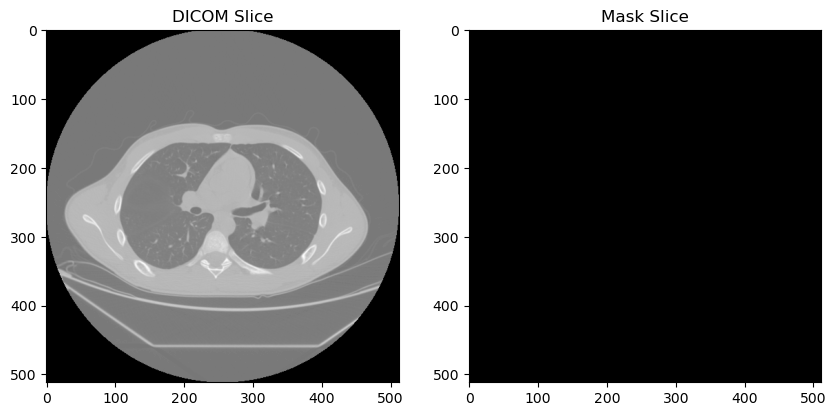

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0009\01-01-2000-NA-NA-83184\3000918.000000-NA-21926
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 10_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\10_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0010\01-01-2000-NA-NA-37629\3000709.000000-NA-50417
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0010\01-01-2000-NA-NA-43375\3000518.000000-NA-66796


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 10


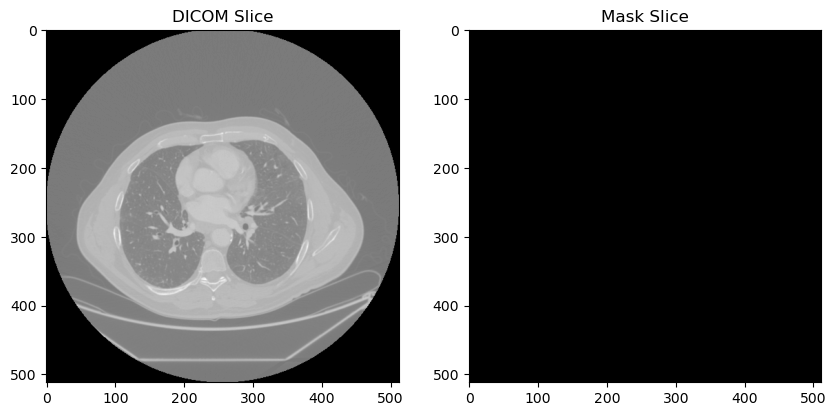


🔍 Mask filename: 11_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\11_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0011\01-01-2000-NA-NA-55602\3000922.000000-NA-50814
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0011\01-01-2000-NA-NA-55602\3000922.000000-NA-50814 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0011\01-01-2000-NA-NA-73568\3000559.000000-NA-23138


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 11


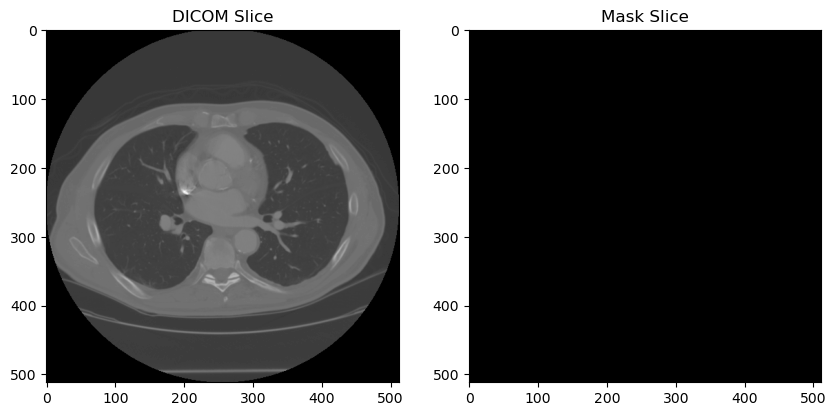


🔍 Mask filename: 12_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\12_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0012\01-01-2000-NA-NA-26735\3000975.000000-NA-50170
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0012\01-01-2000-NA-NA-50667\3000561.000000-NA-57842


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 12


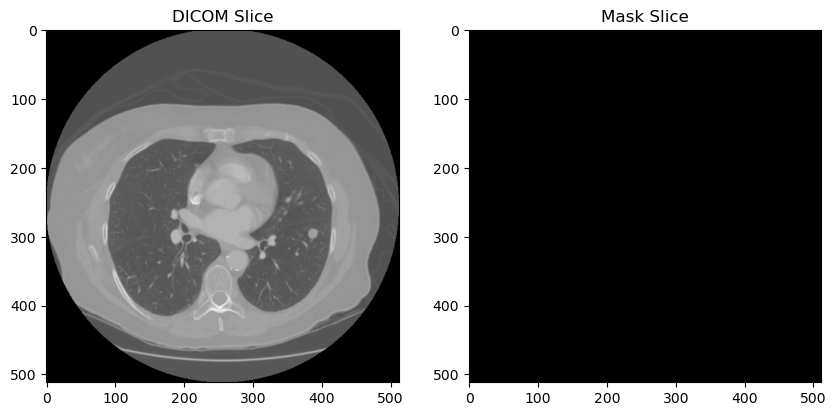


🔍 Mask filename: 13_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\13_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0013\01-01-2000-NA-NA-54750\3000551.000000-NA-80786


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 13


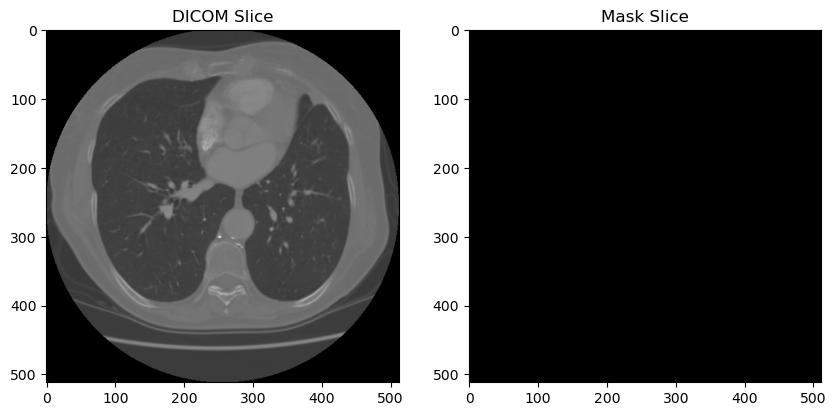

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0013\01-01-2000-NA-NA-87109\3001614.000000-NA-81239
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 14_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\14_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0014\01-01-2000-NA-NA-22969\3000901.000000-NA-48817
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0014\01-01-2000-NA-NA-38612\3000562.000000-NA-07402


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 14


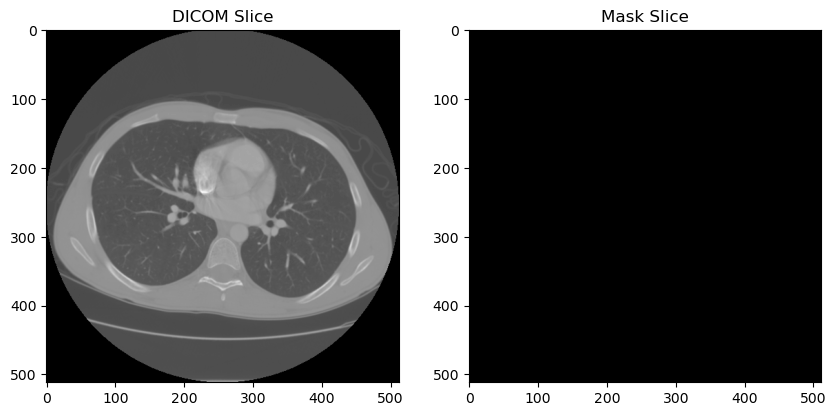


🔍 Mask filename: 15_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\15_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0015\01-01-2000-NA-NA-11146\3000610.000000-NA-28223


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 15


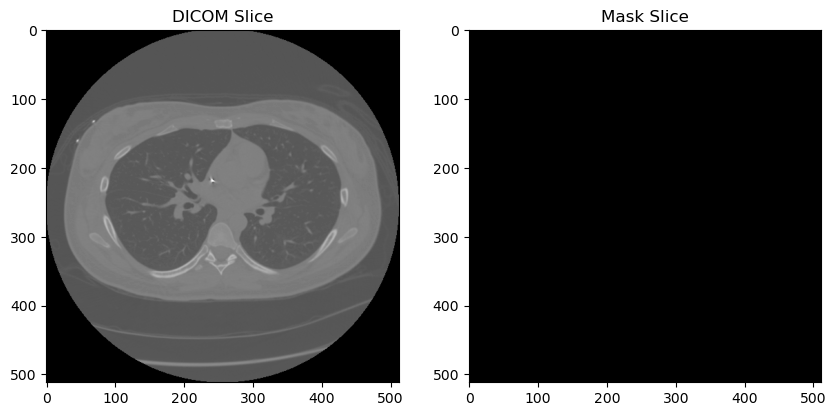

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0015\01-01-2000-NA-NA-11353\3000927.000000-NA-19268
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 16_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\16_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0016\01-01-2000-NA-NA-34278\3000580.000000-NA-73630


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 16


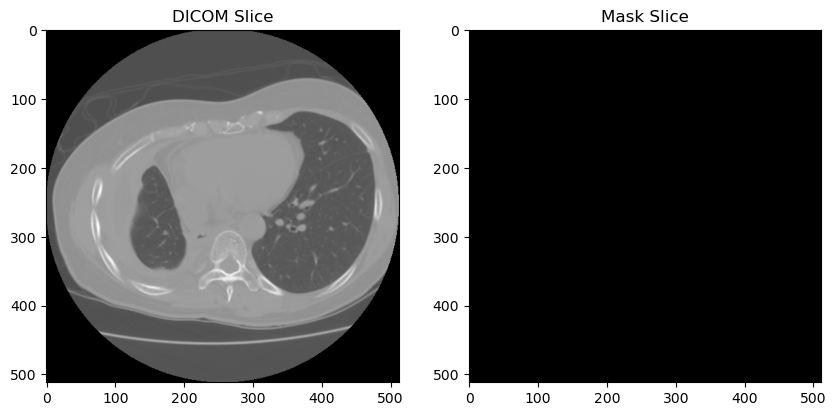

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0016\01-01-2000-NA-NA-91775\3000907.000000-NA-06199
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 17_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\17_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0017\01-01-2000-NA-NA-50745\3000929.000000-NA-91923
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0017\01-01-2000-NA-NA-69301\3000613.000000-NA-28428


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 17


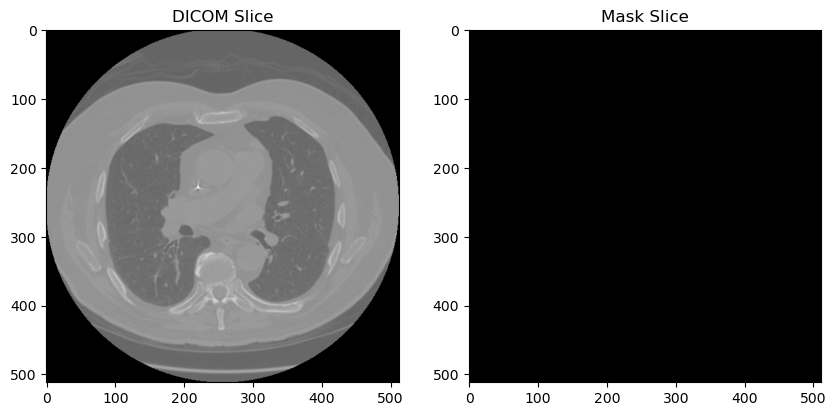


🔍 Mask filename: 18_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\18_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0018\01-01-2000-NA-NA-83659\3000920.000000-NA-92391
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0018\01-01-2000-NA-NA-90263\3000550.000000-NA-10592
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0018\01-01-2000-NA-NA-90263\3000550.000000-NA-10592 due to error:
mask has too few dimensions (number of dimensions 1, minimum required 2)

🔍 Mask filename: 19_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\19_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0019\01-01-2000-NA-NA-70623\3000523.000000-NA-06585


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 19


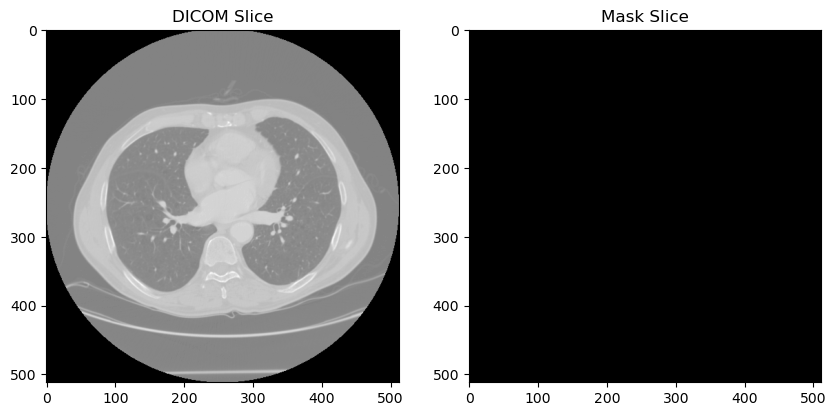

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0019\01-01-2000-NA-NA-81072\3001066.000000-NA-45726
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 20_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\20_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0020\01-01-2000-NA-NA-29935\3000525.000000-NA-47372


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 20


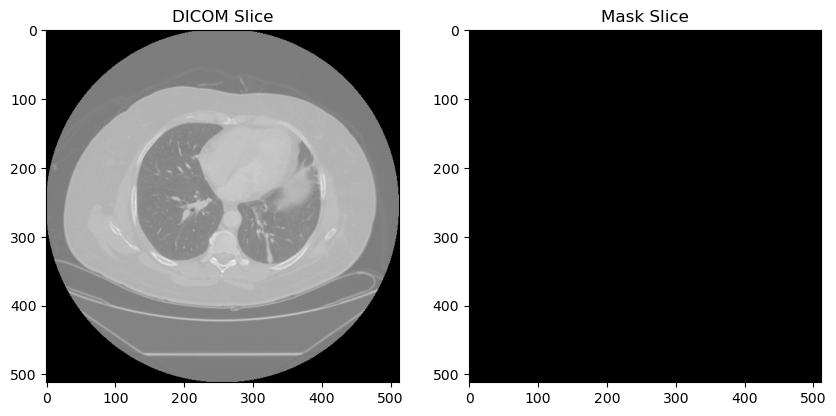

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0020\01-01-2000-NA-NA-85855\3000896.000000-NA-59915
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0020\01-01-2000-NA-NA-85855\3000896.000000-NA-59915 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2011, 2011, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1781, 2011, 1]


🔍 Mask filename: 21_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\21_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0021\01-01-2000-NA-NA-39424\3000719.000000-NA-45434
⚠️ Unusually la

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 21


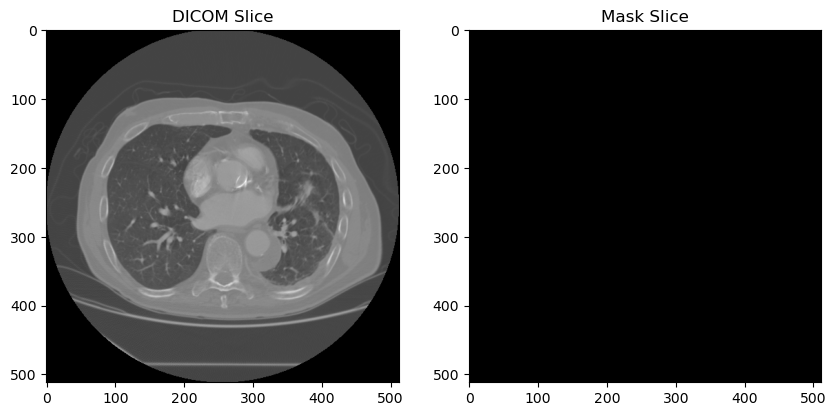


🔍 Mask filename: 22_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\22_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0022\01-01-2000-NA-NA-25074\3001612.000000-NA-91452
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0022\01-01-2000-NA-NA-36179\3000630.000000-NA-50076


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 22


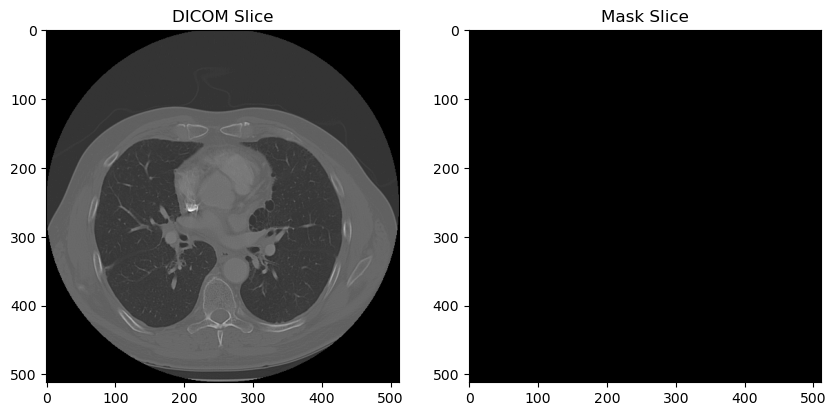


🔍 Mask filename: 23_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\23_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0023\01-01-2000-NA-NA-44207\3000628.000000-NA-26588


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 23


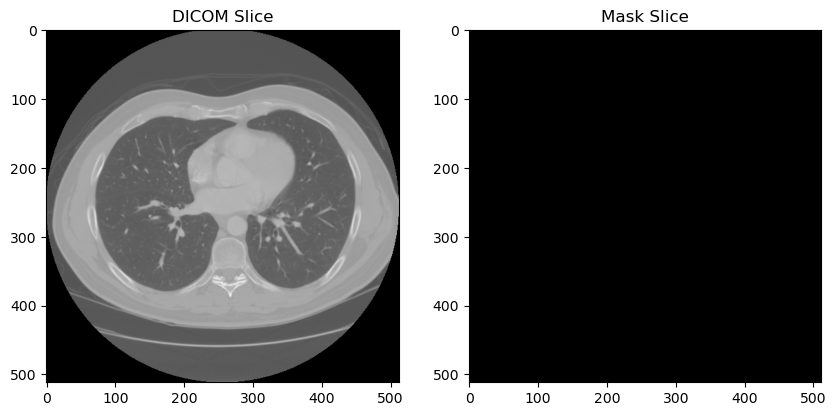

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0023\01-01-2000-NA-NA-54329\3000979.000000-NA-72506
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0023\01-01-2000-NA-NA-54329\3000979.000000-NA-72506 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 24_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\24_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0024\01-01-2000-NA-NA-34802\3000557.000000-NA-80114


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 24


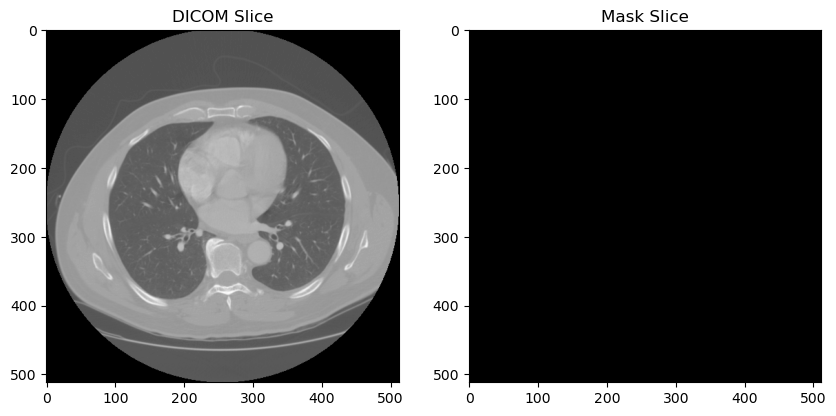

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0024\01-01-2000-NA-NA-50498\3000899.000000-NA-16602
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 25_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\25_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0025\01-01-2000-NA-NA-45655\3000710.000000-NA-36409
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0025\01-01-2000-NA-NA-94910\3000524.000000-NA-53557


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 25


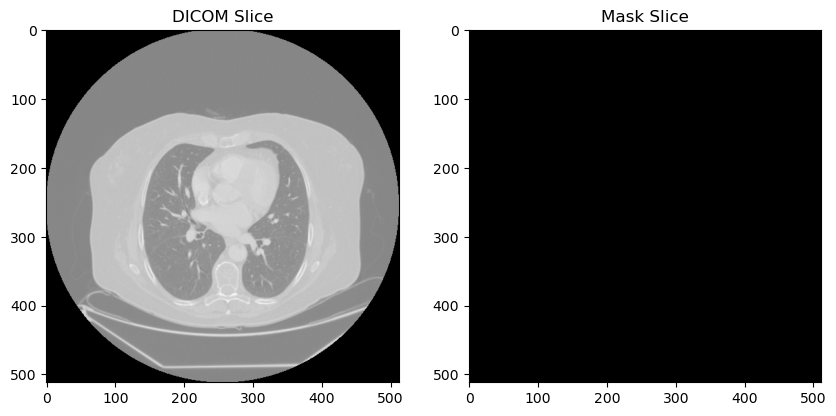


🔍 Mask filename: 26_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\26_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0026\01-01-2000-NA-NA-02665\3000519.000000-NA-40086


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 26


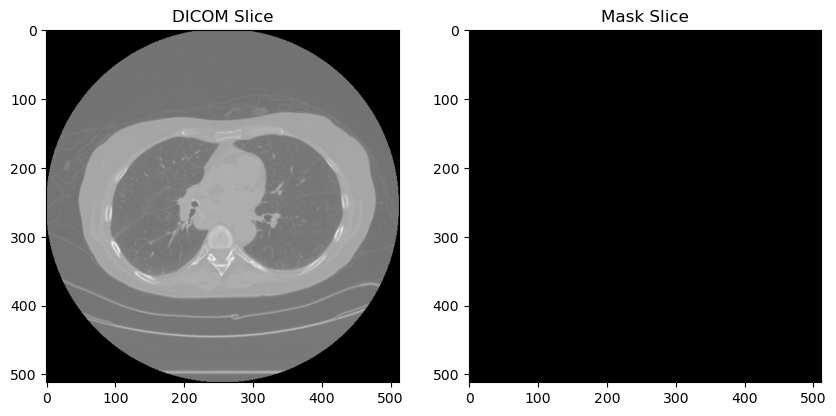

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0026\01-01-2000-NA-NA-23686\3000916.000000-NA-26094
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 27_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\27_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0027\01-01-2000-NA-NA-45559\3000614.000000-NA-12456


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 27


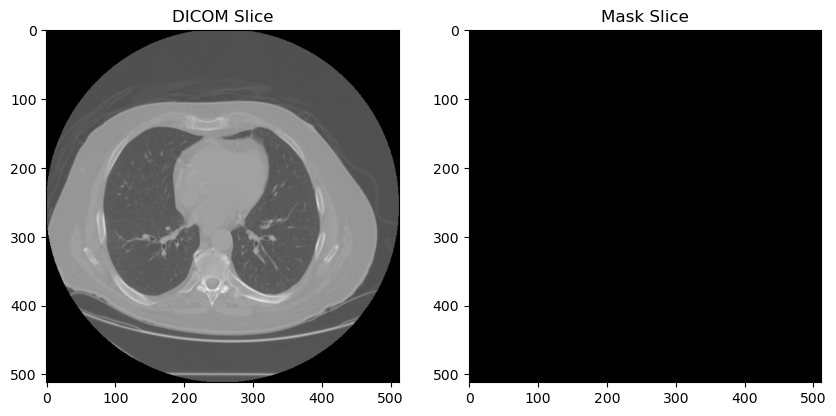

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0027\01-01-2000-NA-NA-57764\3000930.000000-NA-17531
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 29_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\29_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0029\01-01-2000-NA-NA-60452\3000545.000000-NA-94314


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 29


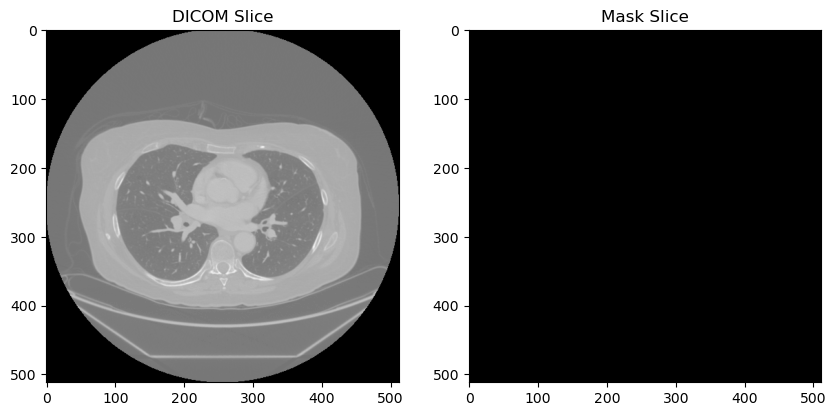

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0029\01-01-2000-NA-NA-85416\3000898.000000-NA-85946
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 30_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\30_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0030\01-01-2000-NA-NA-08815\3000720.000000-NA-12443
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0030\01-01-2000-NA-NA-37865\3000576.000000-NA-43183


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 30


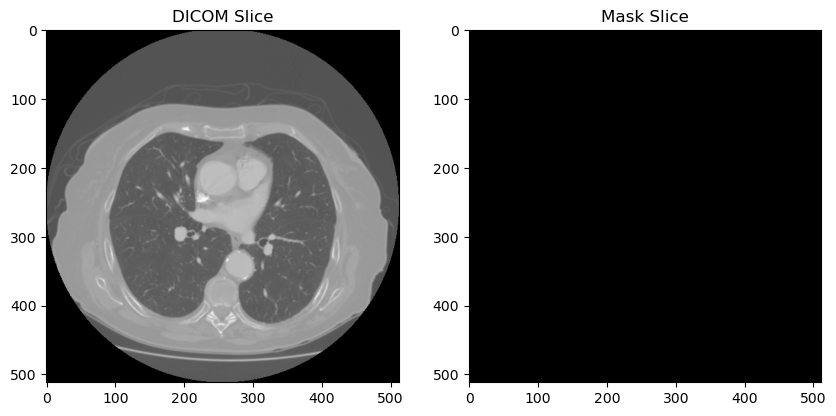


🔍 Mask filename: 31_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\31_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0031\01-01-2000-NA-NA-24294\3000938.000000-NA-36565
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0031\01-01-2000-NA-NA-70739\3000608.000000-NA-60568


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 31


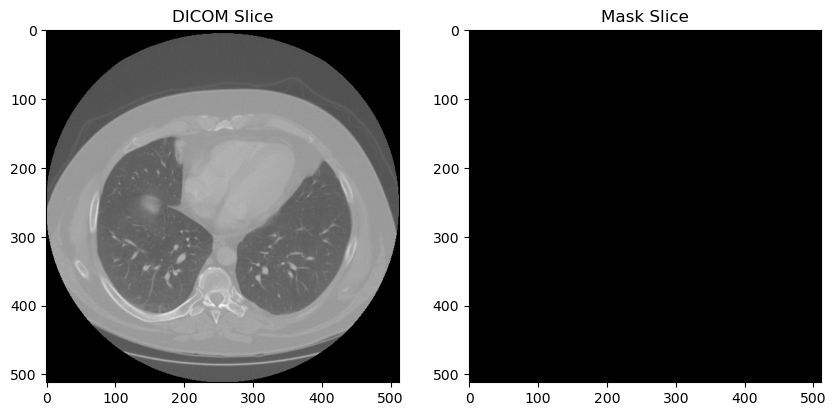


🔍 Mask filename: 33_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\33_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0033\01-01-2000-NA-NA-62529\3000919.000000-NA-55999
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0033\01-01-2000-NA-NA-87807\3000546.000000-NA-83490


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 33


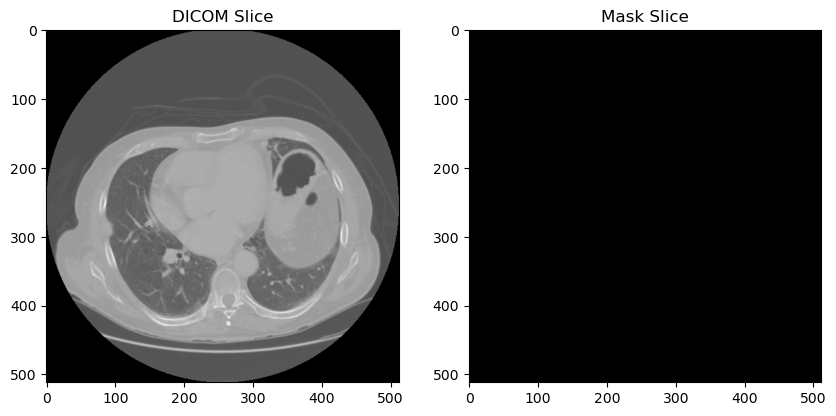


🔍 Mask filename: 34_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\34_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0034\01-01-2000-NA-NA-15343\3000914.000000-NA-23896
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0034\01-01-2000-NA-NA-73045\3000516.000000-NA-32832


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 34


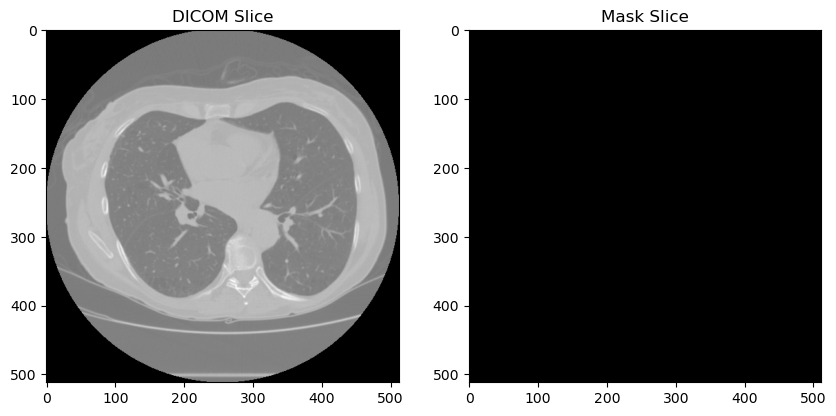


🔍 Mask filename: 35_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\35_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0035\01-01-2000-NA-NA-62152\3000924.000000-NA-86237
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0035\01-01-2000-NA-NA-79332\3000582.000000-NA-98613


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 35


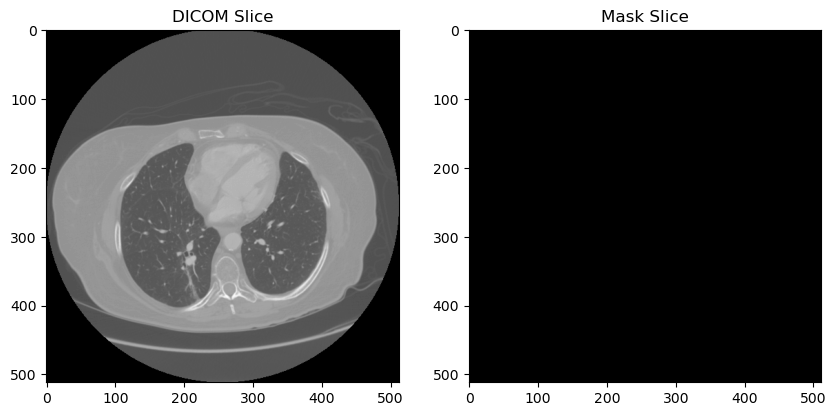


🔍 Mask filename: 36_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\36_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0036\01-01-2000-NA-NA-38467\3001610.000000-NA-43354
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0036\01-01-2000-NA-NA-49231\3000521.000000-NA-18990


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 36


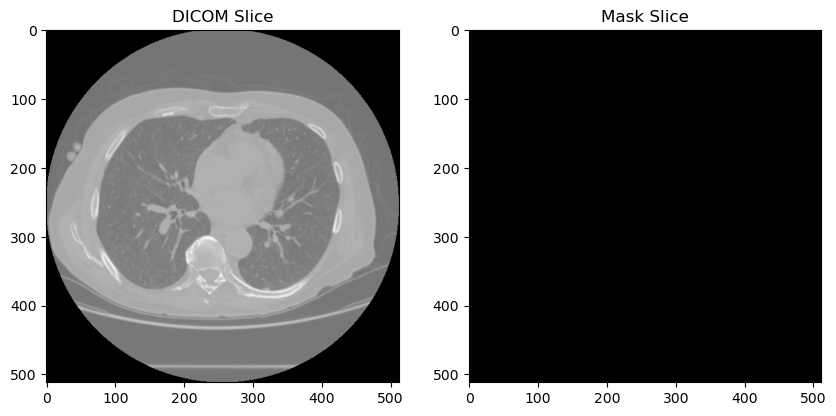


🔍 Mask filename: 37_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\37_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0037\01-01-2000-NA-NA-43829\3000573.000000-NA-12179


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 37


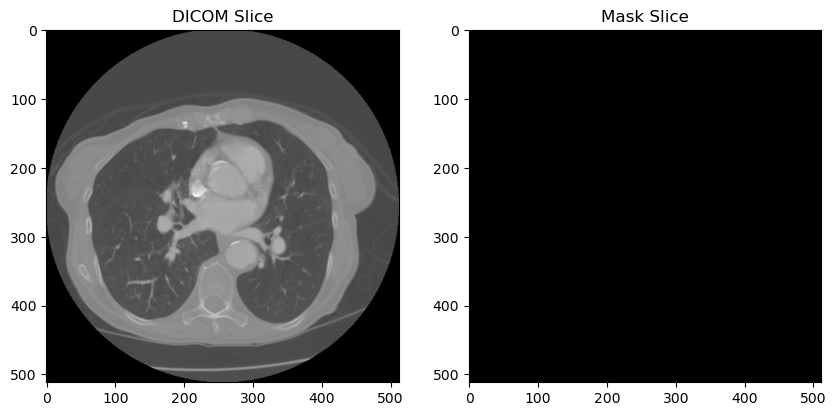

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0037\01-01-2000-NA-NA-96376\3000905.000000-NA-16250
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 38_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\38_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0038\01-01-2000-NA-NA-56678\3000554.000000-NA-82428


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 38


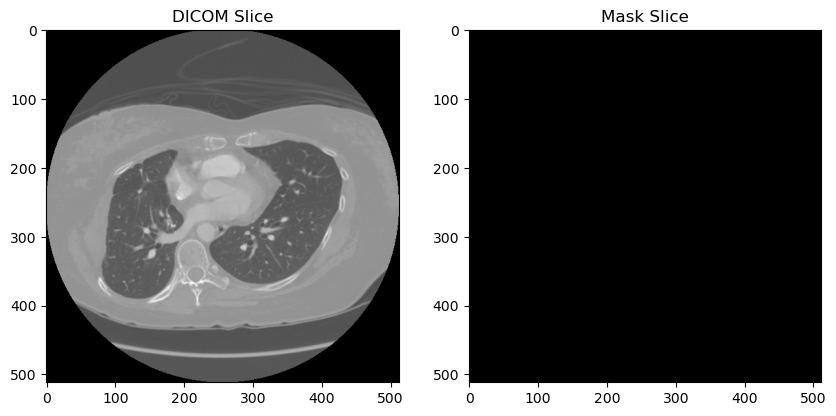

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0038\01-01-2000-NA-NA-89181\3000715.000000-NA-61943
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 39_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\39_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0039\01-01-2000-NA-NA-49300\3000517.000000-NA-01463


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 39


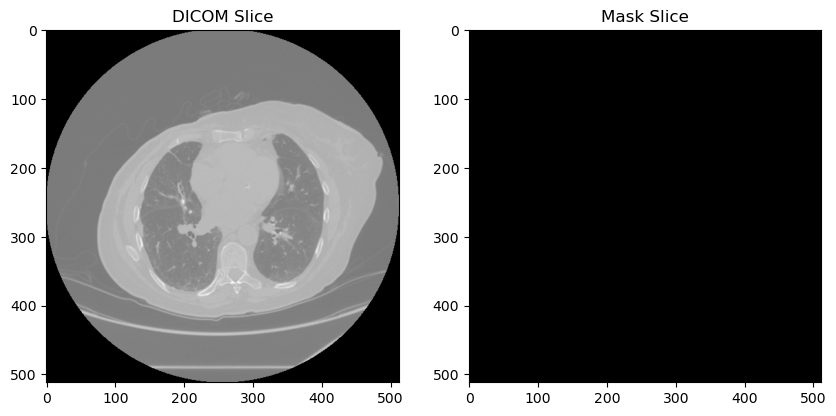

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0039\01-01-2000-NA-NA-73642\3000915.000000-NA-32229
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 40_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\40_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0040\01-01-2000-NA-NA-44543\3000721.000000-NA-25669
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0040\01-01-2000-NA-NA-70857\3000578.000000-NA-33640


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 40


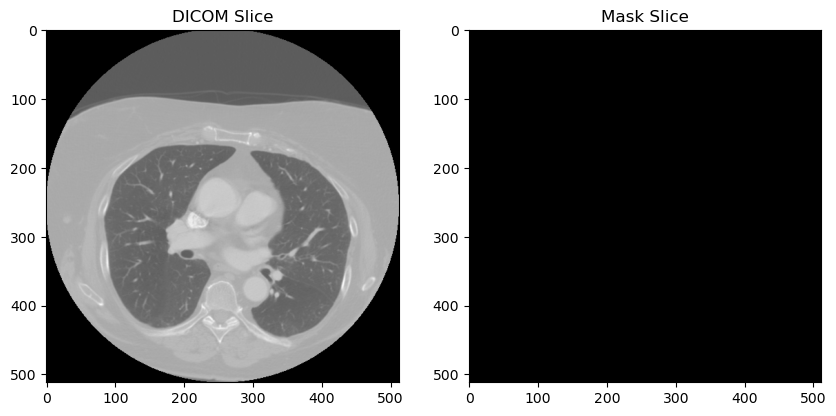


🔍 Mask filename: 41_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\41_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0041\01-01-2000-NA-NA-05025\3000902.000000-NA-97780
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0041\01-01-2000-NA-NA-19169\3000568.000000-NA-87015


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 41


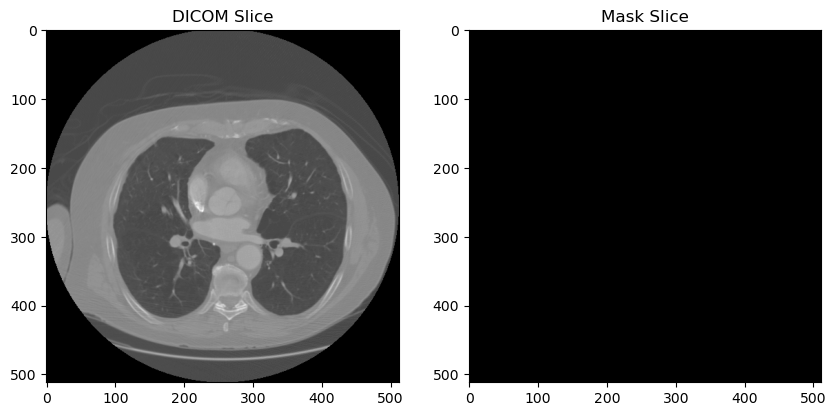


🔍 Mask filename: 42_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\42_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0042\01-01-2000-NA-NA-33377\3000579.000000-NA-20341


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 42


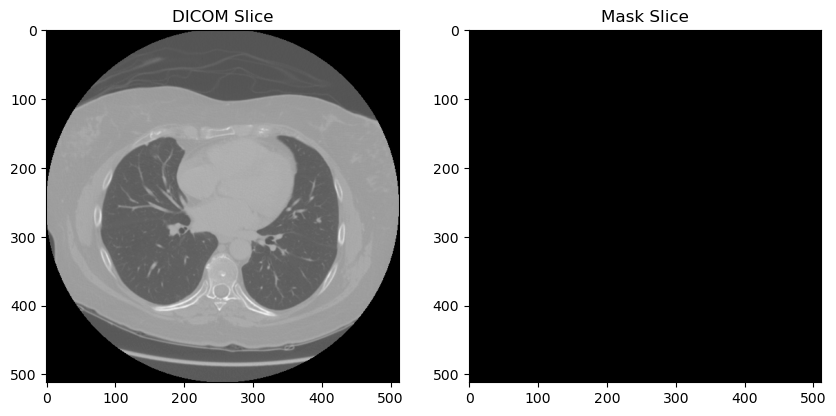

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0042\01-01-2000-NA-NA-73529\3000906.000000-NA-08135
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 43_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\43_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0043\01-01-2000-NA-NA-08605\3000629.000000-NA-31276


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 43


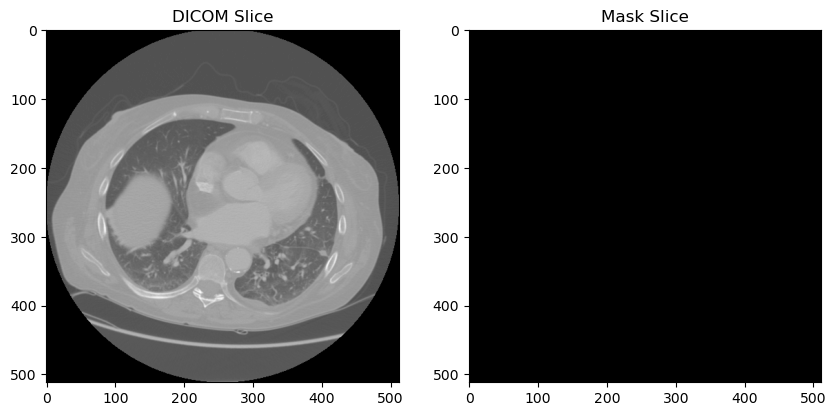

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0043\01-01-2000-NA-NA-41395\3000980.000000-NA-64282
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 44_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\44_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0044\01-01-2000-NA-NA-00114\3000571.000000-NA-93273


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 44


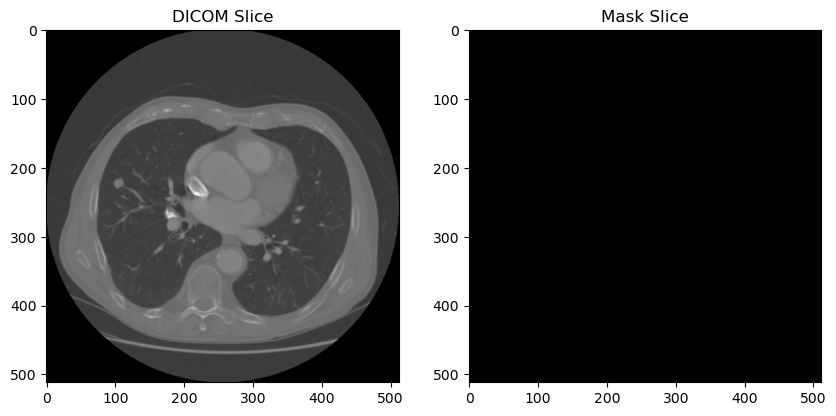

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0044\01-01-2000-NA-NA-25963\3000903.000000-NA-86262
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0044\01-01-2000-NA-NA-25963\3000903.000000-NA-86262 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 45_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\45_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0045\01-01-2000-NA-NA-17703\3000547.000000-NA-78950


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 45


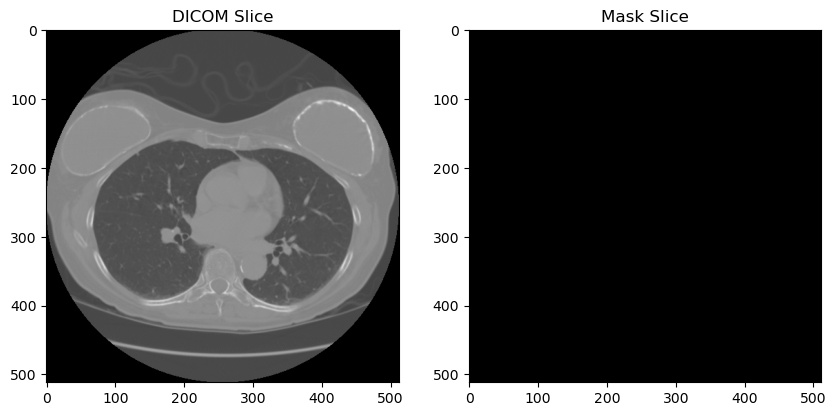

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0045\01-01-2000-NA-NA-58087\3001590.000000-NA-00766
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 46_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\46_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0046\01-01-2000-NA-NA-46577\3000577.000000-NA-66972


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 46


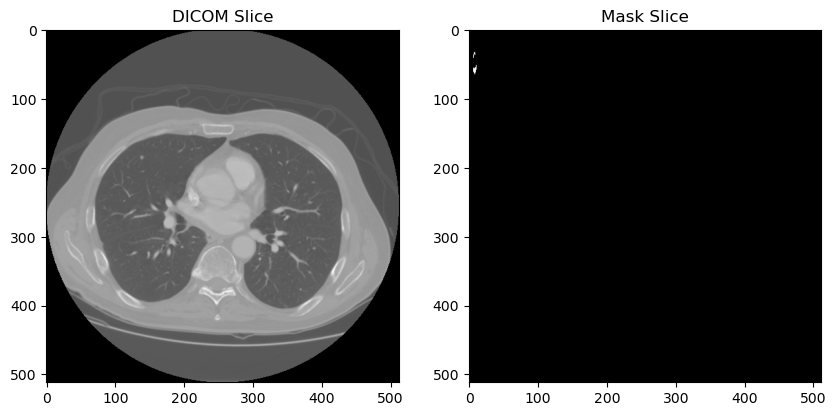

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0046\01-01-2000-NA-NA-49088\3001593.000000-NA-31398
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 47_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\47_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0047\01-01-2000-NA-NA-37097\3000921.000000-NA-18919
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0047\01-01-2000-NA-NA-68025\3000552.000000-NA-80992


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 47


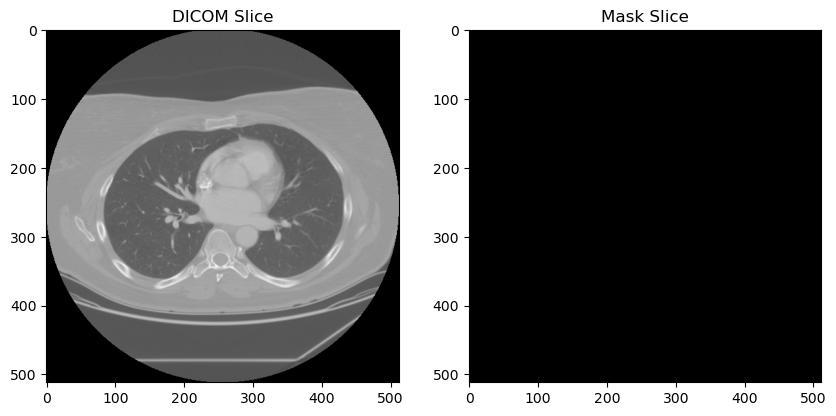


🔍 Mask filename: 48_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\48_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0048\01-01-2000-NA-NA-24306\3000624.000000-NA-03732


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 48


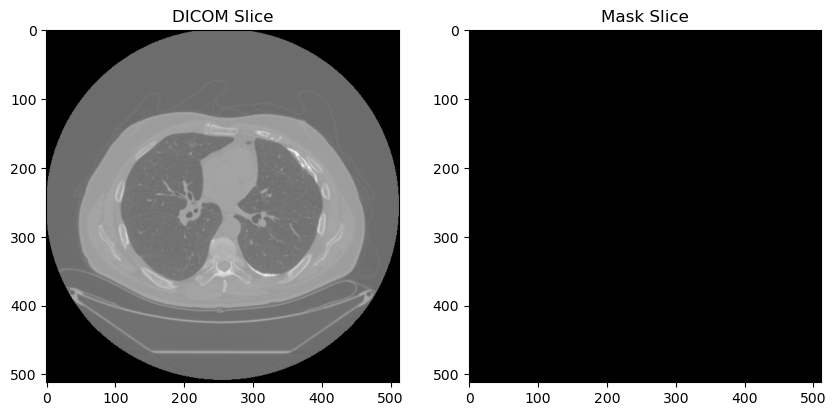

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0048\01-01-2000-NA-NA-87090\3001596.000000-NA-38713
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 49_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\49_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0049\01-01-2000-NA-NA-29746\3001598.000000-NA-66982
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0049\01-01-2000-NA-NA-35347\3000627.000000-NA-75427


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 49


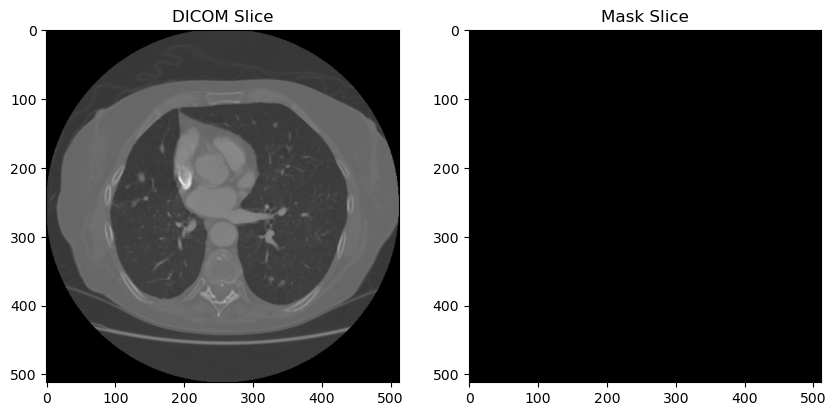


🔍 Mask filename: 50_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\50_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0050\01-01-2000-NA-NA-23199\3000904.000000-NA-53260
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0050\01-01-2000-NA-NA-42493\3000572.000000-NA-36359


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 50


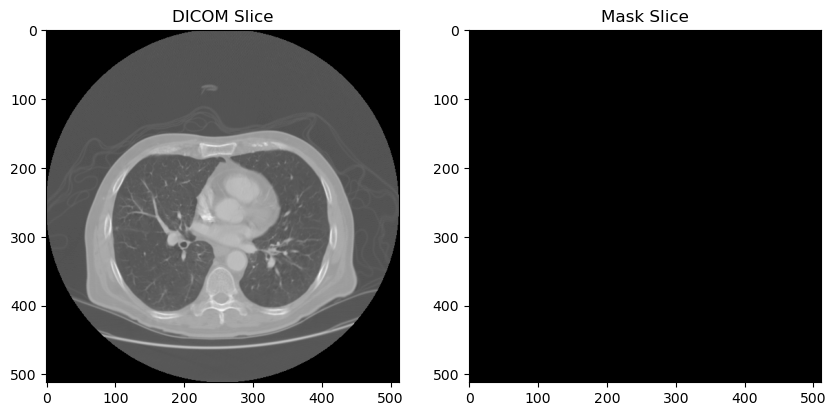


🔍 Mask filename: 51_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\51_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0051\01-01-2000-NA-NA-38292\3000926.000000-NA-62838
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0051\01-01-2000-NA-NA-69899\3000609.000000-NA-22907


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 51


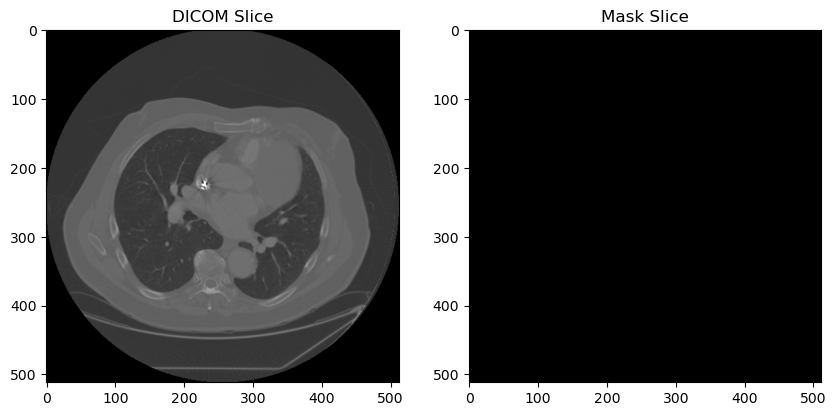


🔍 Mask filename: 52_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\52_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0052\01-01-2000-NA-NA-51420\3000625.000000-NA-20084


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 52


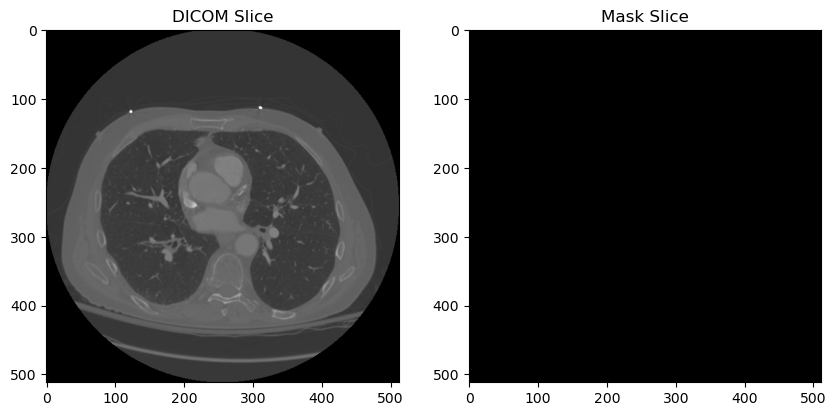

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0052\01-01-2000-NA-NA-87993\3001595.000000-NA-37316
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 53_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\53_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0053\01-01-2000-NA-NA-21938\3000615.000000-NA-59071


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 53


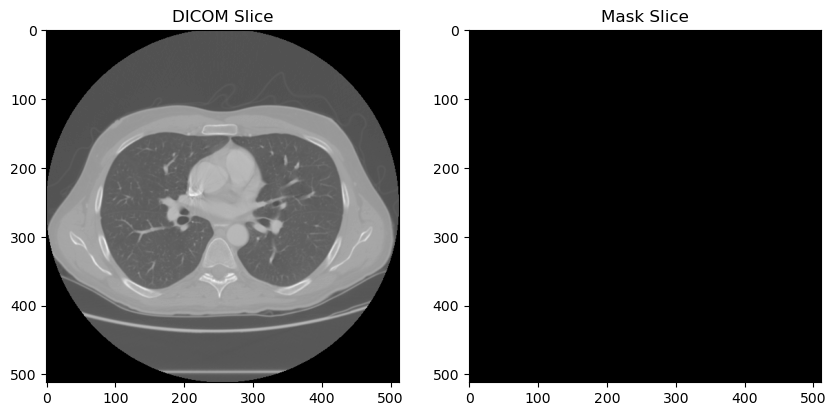

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0053\01-01-2000-NA-NA-80964\3002014.000000-NA-34671
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 54_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\54_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0054\01-01-2000-NA-NA-05483\3000565.000000-NA-60291


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 54


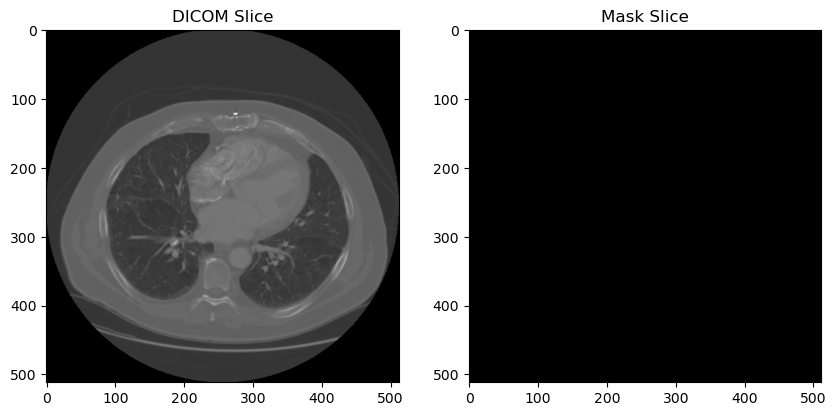

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0054\01-01-2000-NA-NA-21893\3000977.000000-NA-28044
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0054\01-01-2000-NA-NA-21893\3000977.000000-NA-28044 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 55_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\55_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0055\01-01-2000-NA-NA-26492\3000908.000000-NA-34320
⚠️ Unusually la

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 55


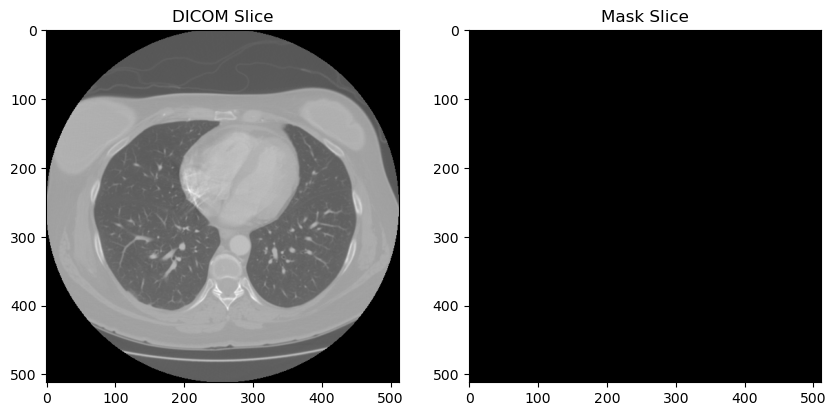


🔍 Mask filename: 56_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\56_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0056\01-01-2000-NA-NA-28488\3000712.000000-NA-13937
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0056\01-01-2000-NA-NA-35375\3000535.000000-NA-98069


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 56


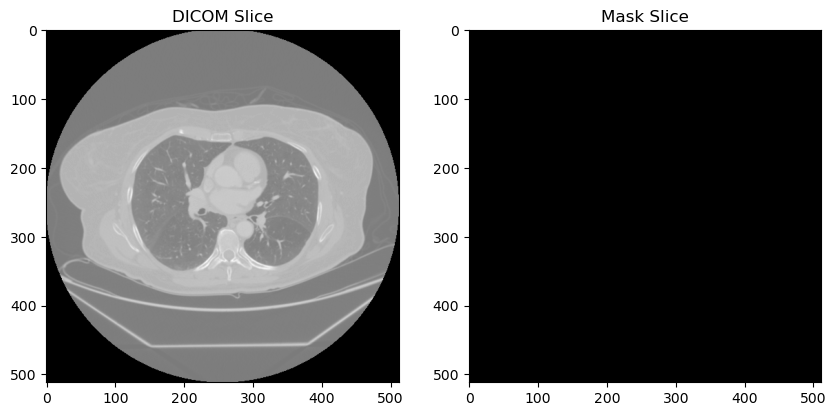


🔍 Mask filename: 57_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\57_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0057\01-01-2000-NA-NA-03262\3000514.000000-NA-56951


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 57


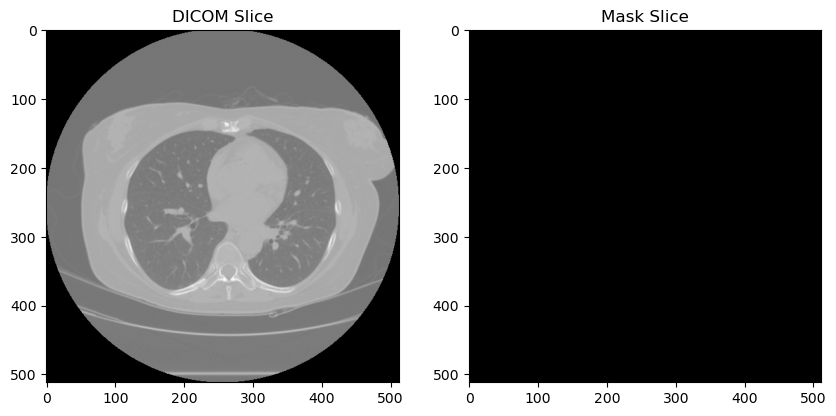

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0057\01-01-2000-NA-NA-56292\3000895.000000-NA-04898
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 58_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\58_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0058\01-01-2000-NA-NA-10975\3001597.000000-NA-31510
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0058\01-01-2000-NA-NA-75706\3000626.000000-NA-00770


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 58


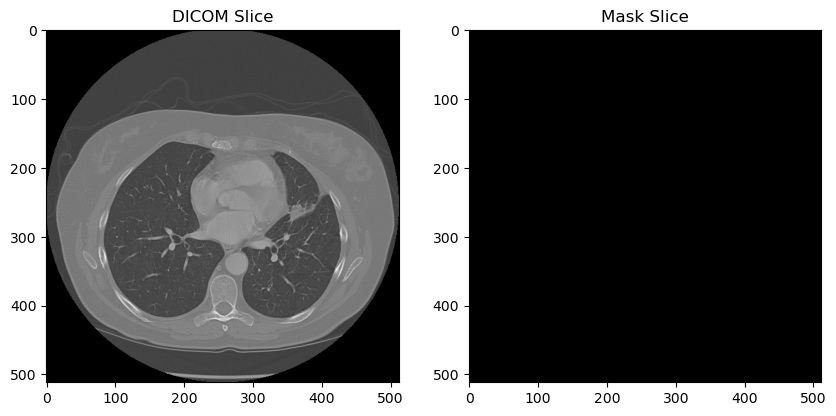


🔍 Mask filename: 59_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\59_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0059\01-01-2000-NA-NA-67090\3000564.000000-NA-48912


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 59


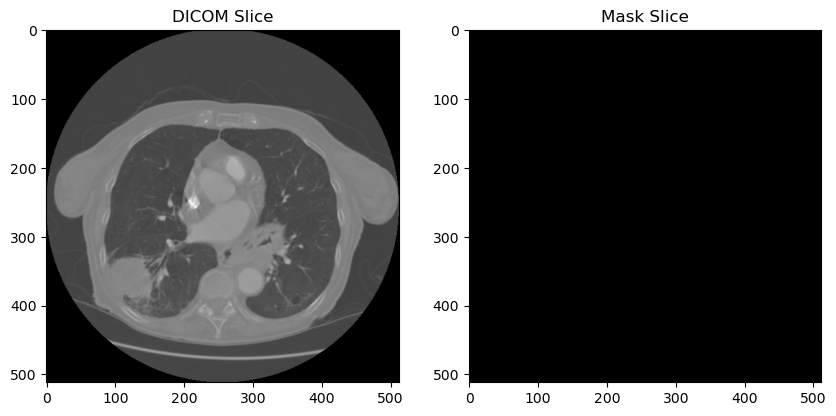

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0059\01-01-2000-NA-NA-86702\3000976.000000-NA-47990
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 60_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\60_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0060\01-01-2000-NA-NA-03997\3001592.000000-NA-27810
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0060\01-01-2000-NA-NA-18382\3000575.000000-NA-55115


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 60


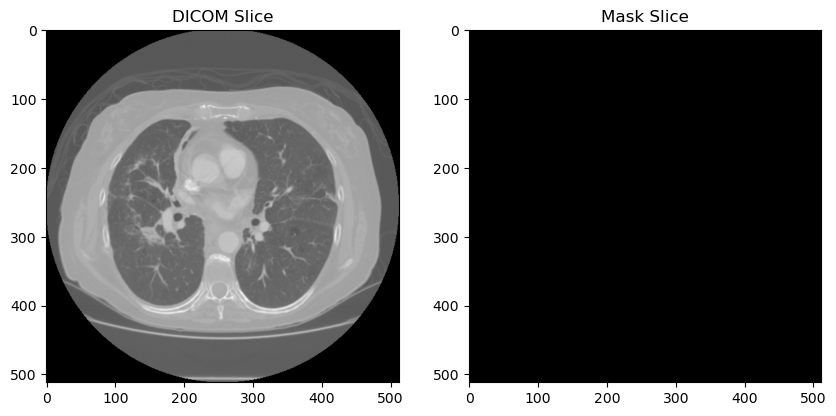


🔍 Mask filename: 61_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\61_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0061\01-01-2000-NA-NA-37302\3000900.000000-NA-75170
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0061\01-01-2000-NA-NA-64840\3000560.000000-NA-47886


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 61


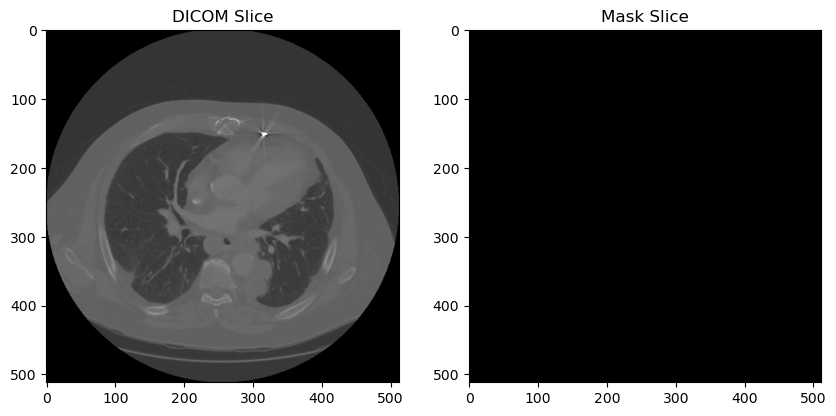


🔍 Mask filename: 63_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\63_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0063\01-01-2000-NA-NA-09873\3000716.000000-NA-25884
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0063\01-01-2000-NA-NA-09873\3000716.000000-NA-25884 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0063\01-01-2000-NA-NA-51316\3000555.000000-NA-81128


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 63


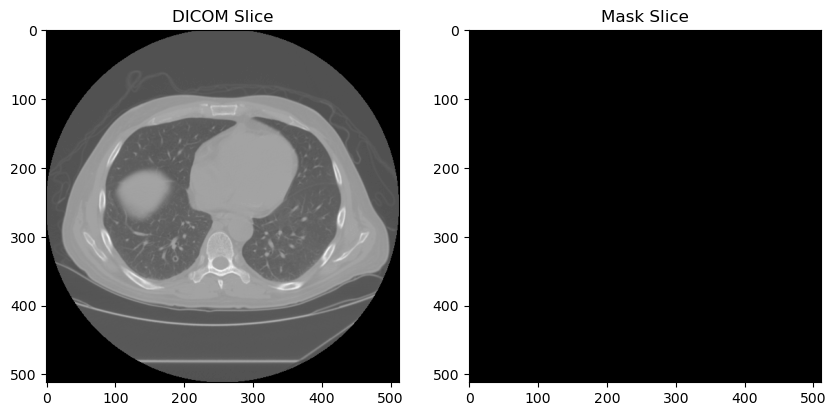


🔍 Mask filename: 64_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\64_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0064\01-01-2000-NA-NA-71210\3000612.000000-NA-48666


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 64


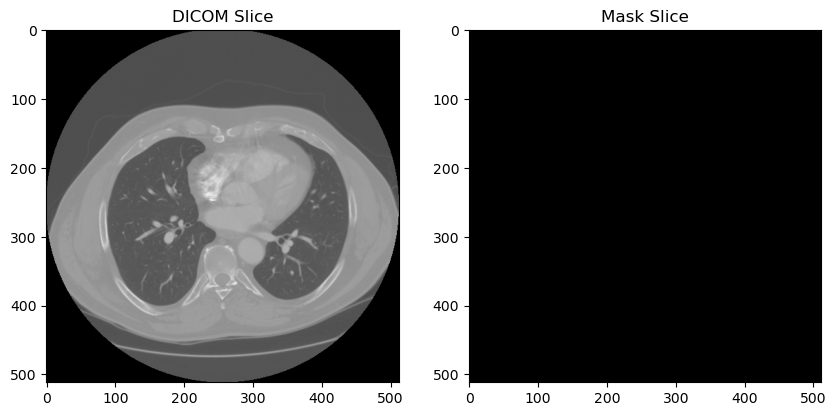

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0064\01-01-2000-NA-NA-77846\3000928.000000-NA-60587
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0064\01-01-2000-NA-NA-77846\3000928.000000-NA-60587 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1836, 2022, 1]


🔍 Mask filename: 65_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\65_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0065\01-01-2000-NA-NA-03808\3000536.000000-NA-68085


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 65


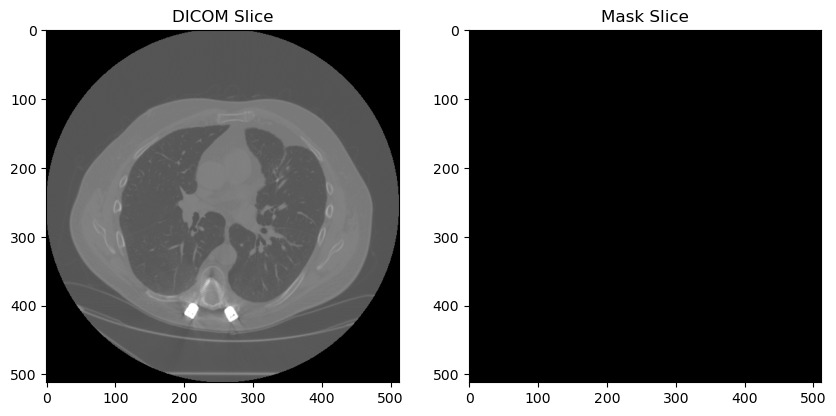

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0065\01-01-2000-NA-NA-23346\3000713.000000-NA-42512
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 66_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\66_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0066\01-01-2000-NA-NA-25332\5576.000000-EASERV0.5mmB50f-00410


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 66


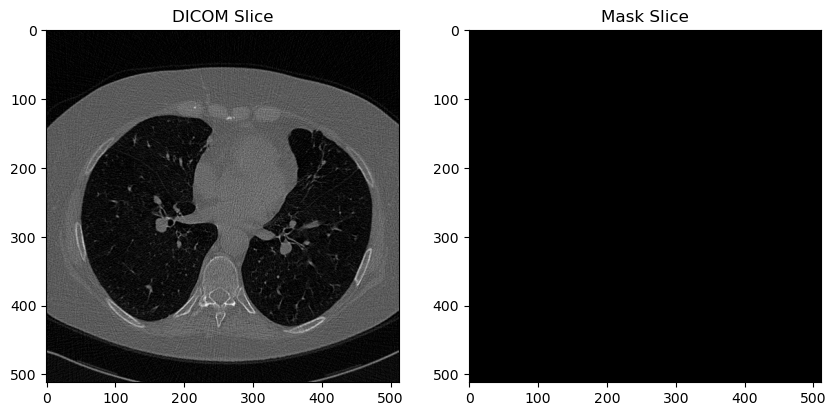

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0066\01-01-2000-NA-NA-57395\5569.000000-W Chest PA-43647
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 67_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\67_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0067\01-01-2000-NA-NA-71158\3000708.000000-NA-21600


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 67


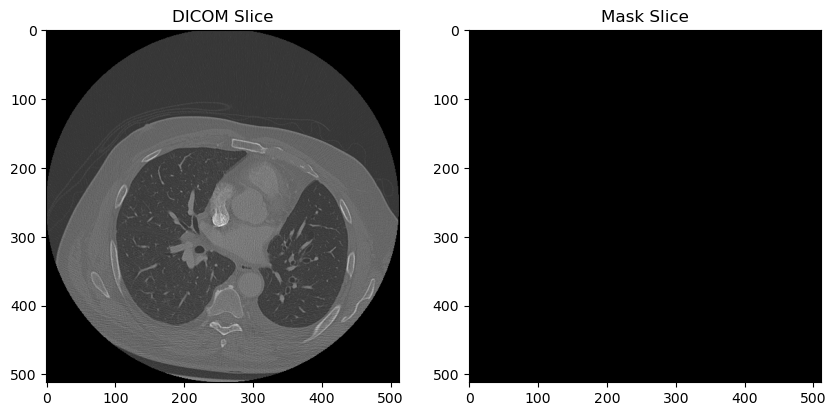

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0067\01-01-2000-NA-NA-96244\3001615.000000-NA-46975
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 68_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\68_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0068\01-01-2000-NA-CHEST PA - LAT-67107\22137.000000-CHEST PA - LAT-12560
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0068\01-01-2000-NA-CT CHEST W CONT-80168\4.000000-Recon 3 CT CHEST-26125


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 68


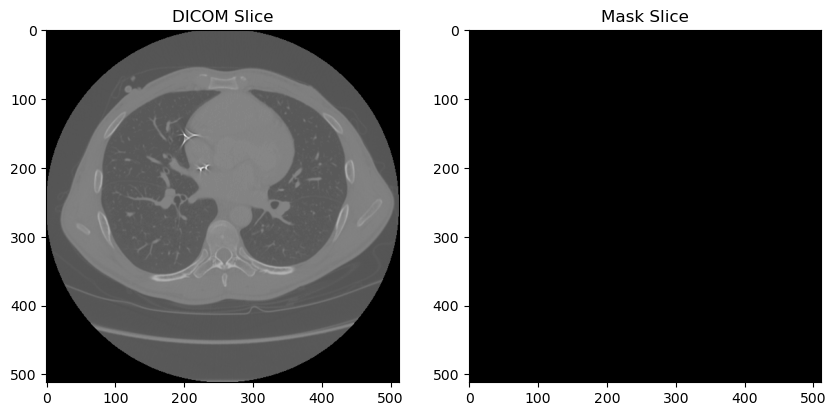


🔍 Mask filename: 69_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\69_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0069\01-01-2000-NA-NA-11368\3083.000000-W Chest PA-96731
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0069\01-01-2000-NA-NA-29787\3079.000000-NA-04249


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 69


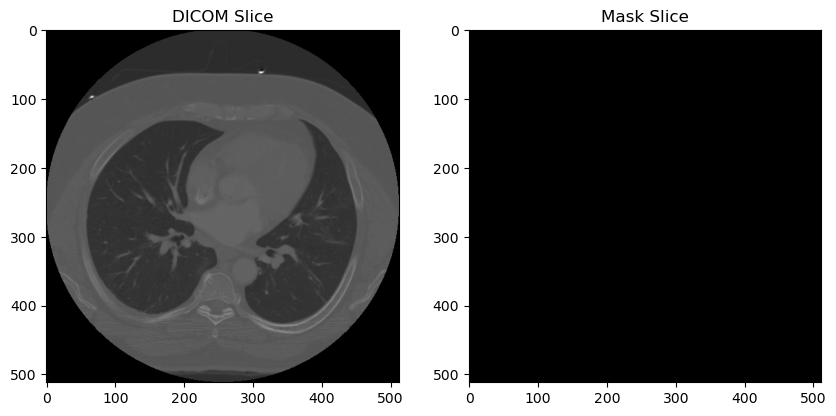


🔍 Mask filename: 70_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\70_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0070\01-01-2000-NA-NA-59500\3000667.000000-NA-54720


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 70


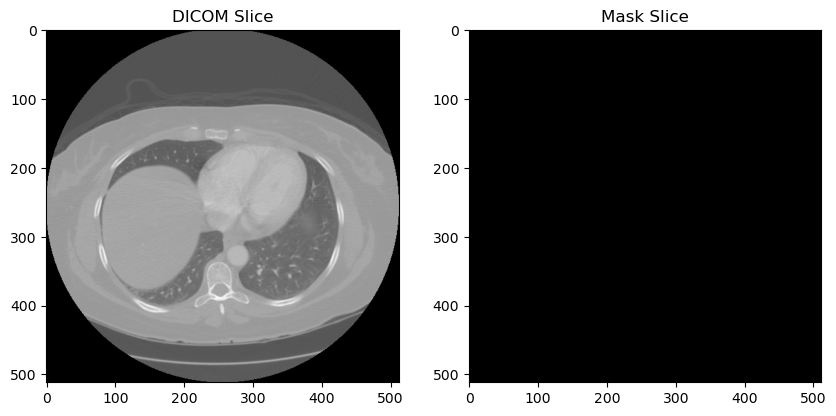

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0070\01-01-2000-NA-NA-72718\3000990.000000-NA-68993
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 72_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\72_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0072\01-01-2000-NA-CHEST PA - LAT-09981\15478.000000-Chest pa-43410
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0072\01-01-2000-NA-CT CHEST W CONT-45499\4.000000-Recon 3-88650


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 72


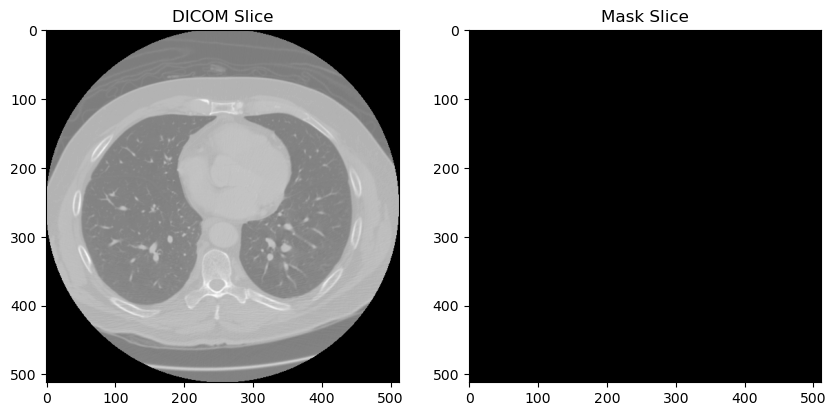


🔍 Mask filename: 73_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\73_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0073\01-01-2000-NA-NA-44963\3000698.000000-NA-25932


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 73


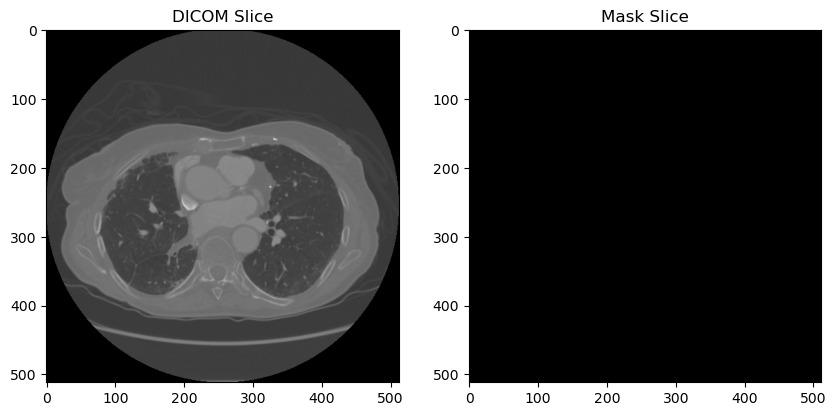

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0073\01-01-2000-NA-NA-53307\3000996.000000-NA-09667
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 74_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\74_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0074\01-01-2000-NA-NA-21544\3000704.000000-NA-44897


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 74


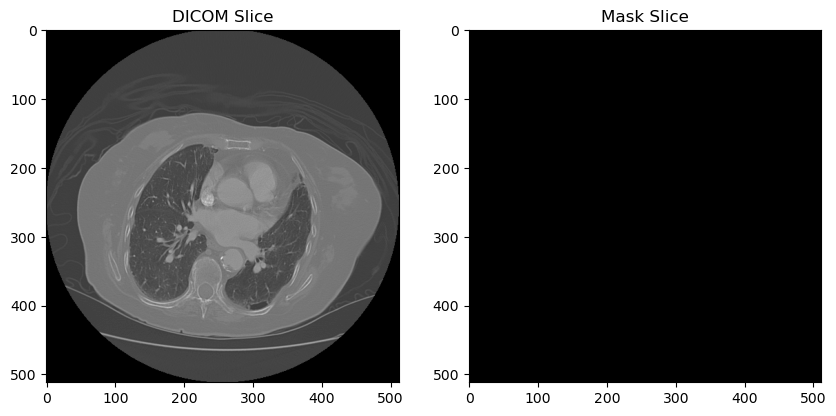

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0074\01-01-2000-NA-NA-89413\3001581.000000-NA-24643
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 75_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\75_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0075\01-01-2000-NA-NA-14796\30083.000000-NA-95222


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 75


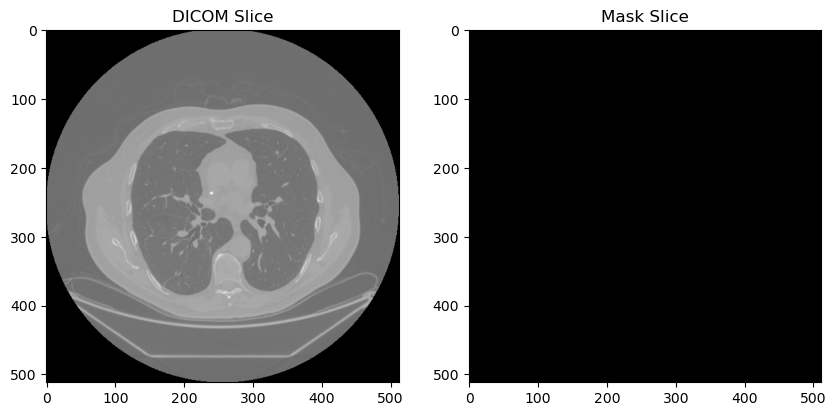

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0075\01-01-2000-NA-NA-27877\30088.000000-NA-39049
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 76_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\76_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0076\01-01-2000-NA-NA-71747\3001587.000000-NA-88013
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0076\01-01-2000-NA-NA-87685\3000734.000000-NA-93071


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 76


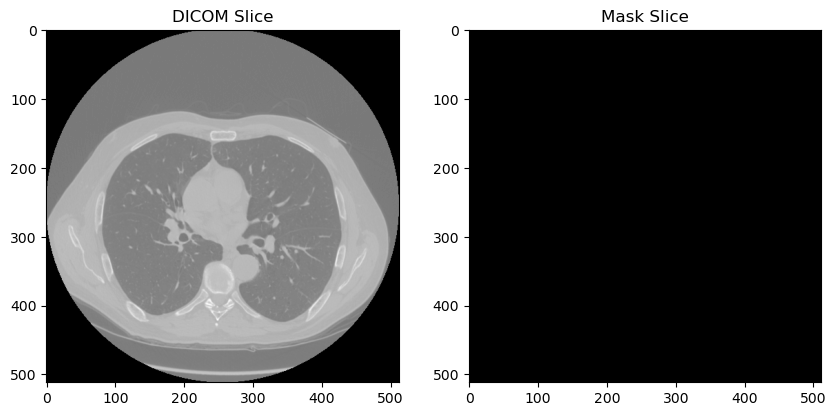


🔍 Mask filename: 77_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\77_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0077\01-01-2000-NA-NA-74706\3000706.000000-NA-80131


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 77


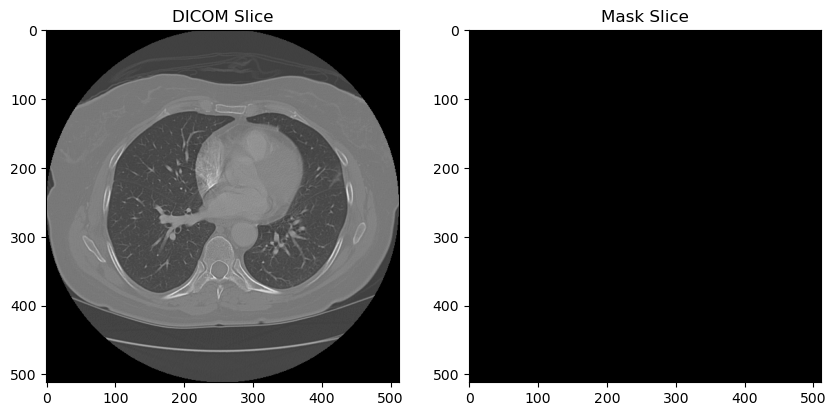

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0077\01-01-2000-NA-NA-98371\3001583.000000-NA-61842
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0077\01-01-2000-NA-NA-98371\3001583.000000-NA-61842 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageSeriesReader.hxx:355:
ITK ERROR: ImageSeriesReader(000001679C6D2410): Size mismatch! The size of  C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0077\01-01-2000-NA-NA-98371\3001583.000000-NA-61842/1-2.dcm is [1792, 2021, 1] and does not match the required size [1783, 2021, 1] from file C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0077\01-01-2000-NA-NA-98371\3001583.000000-NA-61842/1-1.dcm

🔍 Mask filename: 78_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\78_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 78


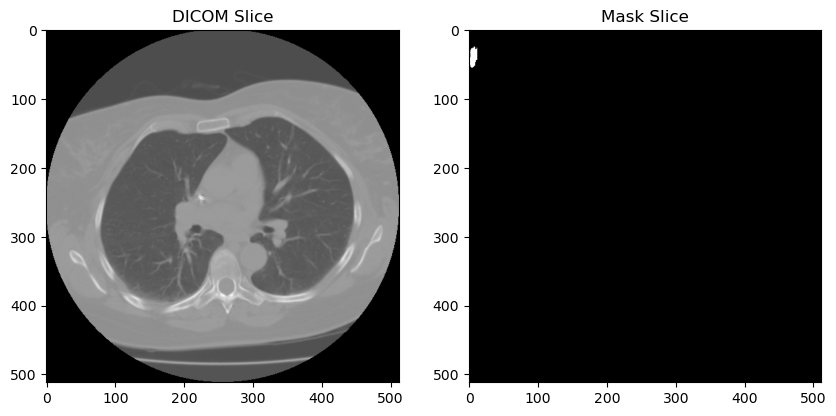


🔍 Mask filename: 79_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\79_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0079\01-01-2000-NA-NA-37490\3278.000000-NA-05159


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 79


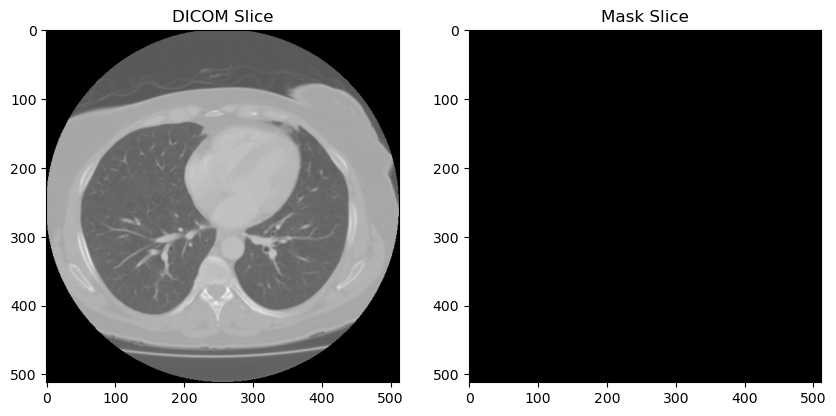

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0079\01-01-2000-NA-NA-50529\3277.000000-W Chest PA-54409
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 80_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\80_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0080\01-01-2000-NA-NA-04258\3001586.000000-NA-27315
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0080\01-01-2000-NA-NA-38073\3000733.000000-NA-81782


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 80


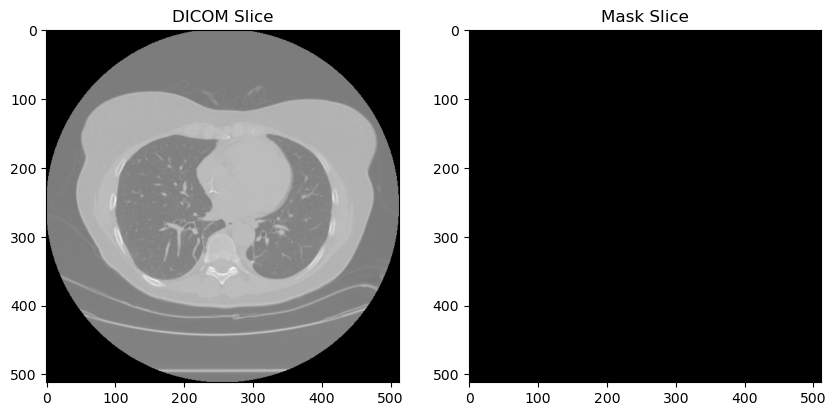


🔍 Mask filename: 81_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\81_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0081\01-01-2000-NA-NA-04821\3000649.000000-NA-44726


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 81


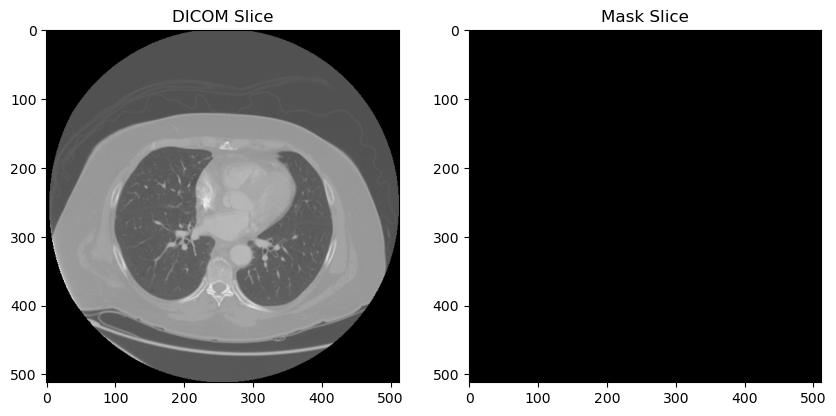

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0081\01-01-2000-NA-NA-67696\3000987.000000-NA-91956
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0081\01-01-2000-NA-NA-67696\3000987.000000-NA-91956 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 82_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\82_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0082\01-01-2000-NA-NA-79176\3000701.000000-NA-44822


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 82


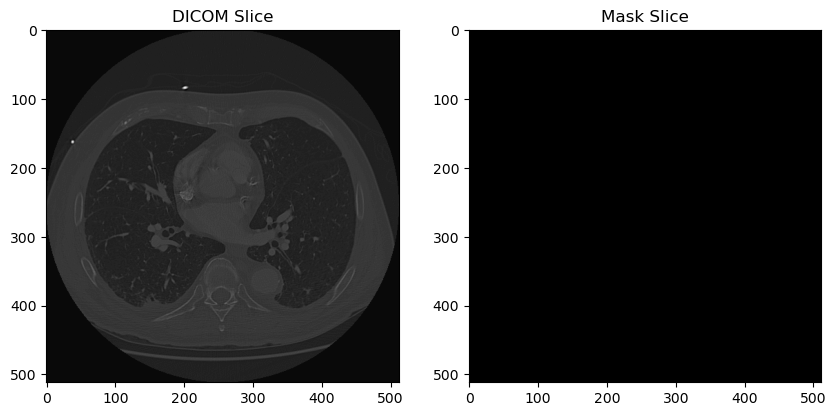

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0082\01-01-2000-NA-NA-96503\3001578.000000-NA-15293
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 83_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\83_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0083\01-01-2000-NA-NA-01452\3001600.000000-NA-28325
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0083\01-01-2000-NA-NA-22049\3000646.000000-NA-60532


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 83


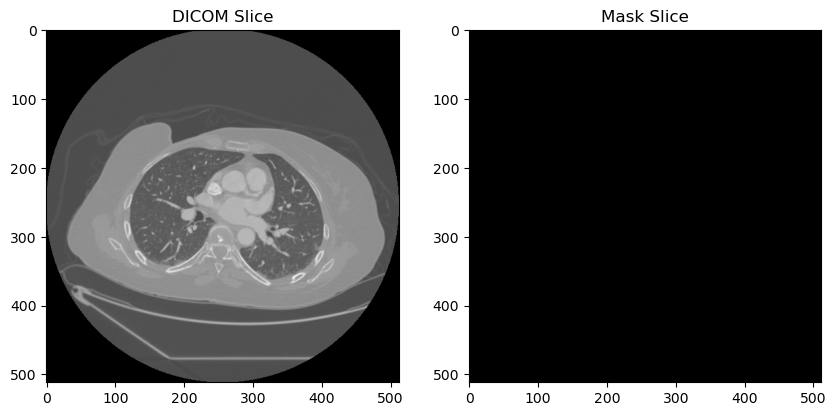


🔍 Mask filename: 84_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\84_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0084\01-01-2000-NA-NA-12869\3210.000000-NA-19980
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0084\01-01-2000-NA-NA-27940\3211.000000-NA-79503


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 84


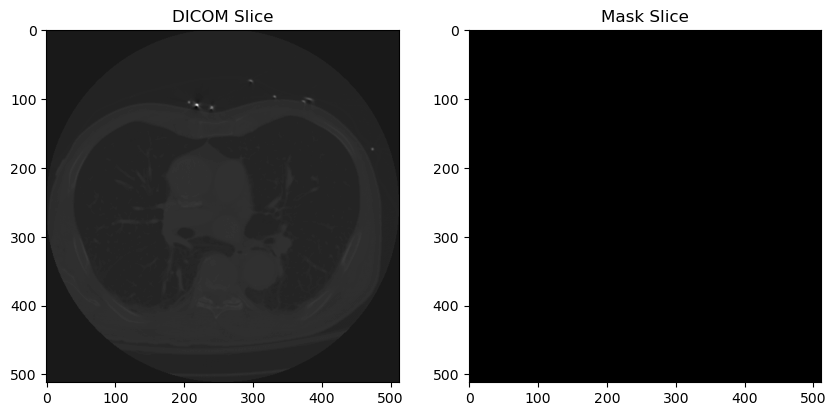


🔍 Mask filename: 85_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\85_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0085\01-01-2000-NA-NA-59145\30089.000000-NA-43489
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0085\01-01-2000-NA-NA-96172\30084.000000-NA-46659


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 85


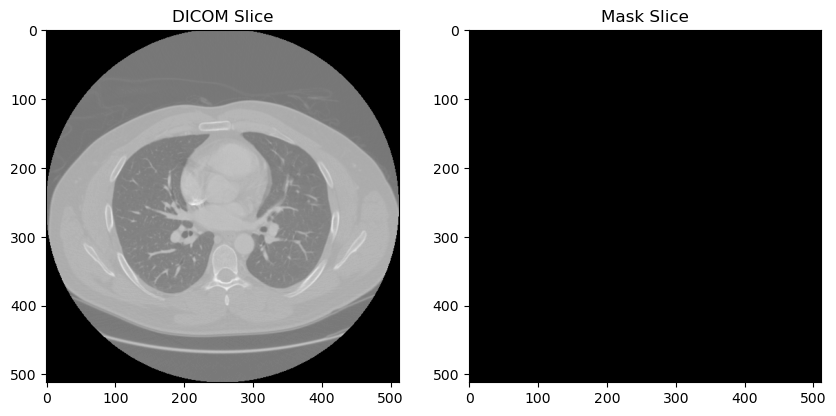


🔍 Mask filename: 86_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\86_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0086\01-01-2000-NA-NA-20589\5603.000000-W Chest PA-60852
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0086\01-01-2000-NA-NA-47717\5604.000000-TAA  3.0  B30f-44879


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 86


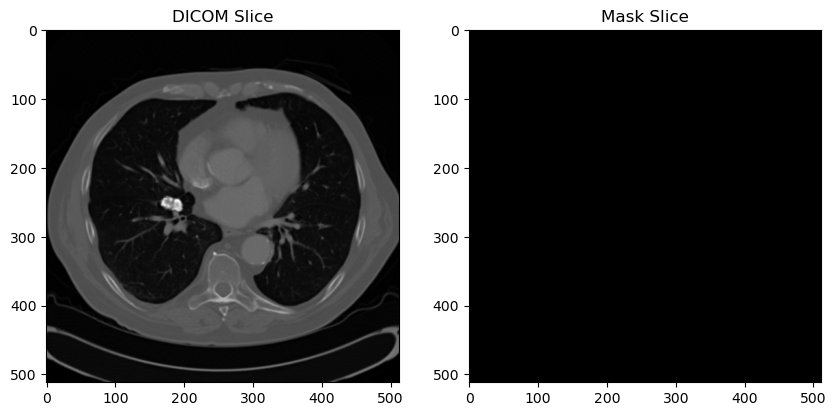


🔍 Mask filename: 87_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\87_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0087\01-01-2000-NA-NA-68125\3000640.000000-NA-85809


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 87


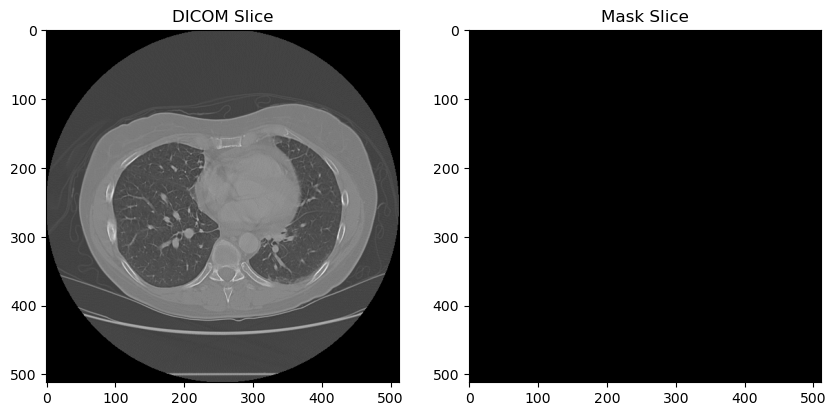

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0087\01-01-2000-NA-NA-74656\3000983.000000-NA-05943
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 88_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\88_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0088\01-01-2000-NA-CHEST PA - LAT-57508\40887.000000-CHEST PA - LAT-73368
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0088\01-01-2000-NA-CT CHABPEL WO-92527\4.000000-Recon 3-02075


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 88


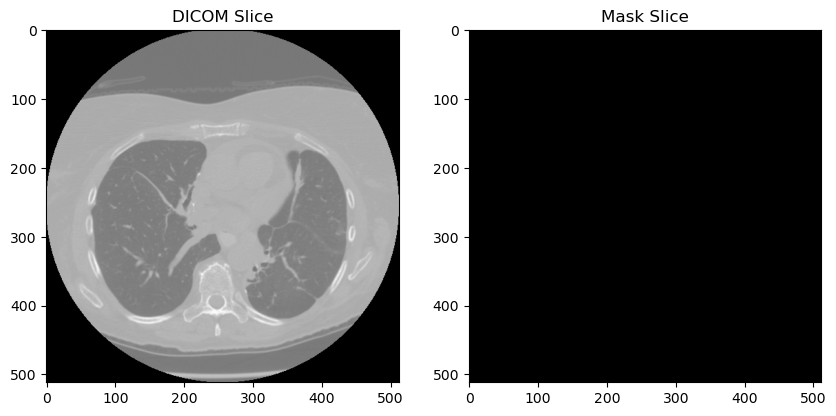


🔍 Mask filename: 89_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\89_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0089\01-01-2000-NA-NA-75504\3000707.000000-NA-55268


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 89


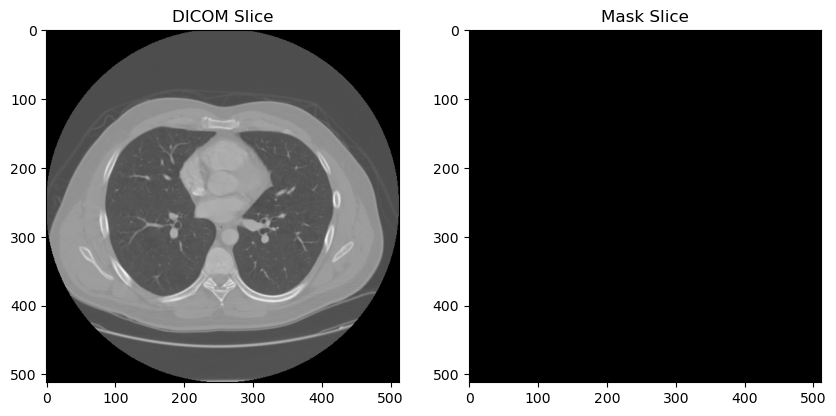

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0089\01-01-2000-NA-NA-77819\3001584.000000-NA-40983
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0089\01-01-2000-NA-NA-77819\3001584.000000-NA-40983 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 90_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\90_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0090\01-01-2000-NA-CHEST PA  LATERAL-15136\29869.000000-CHEST PA  L

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 90


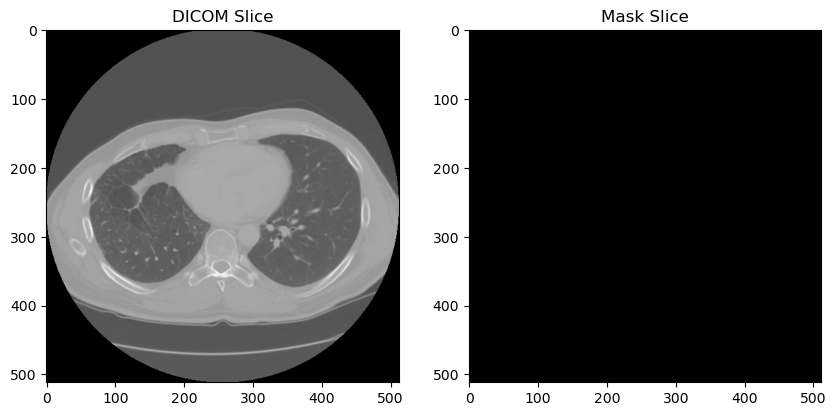


🔍 Mask filename: 91_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\91_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0091\01-01-2000-NA-CHEST 2 VIEW-13251\39464.000000-CHEST 2 VIEW-77903
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0091\01-01-2000-NA-CT ANGIO CHEST WWO C-79589\2.000000-BOTTOM TO TOP-78441


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 91


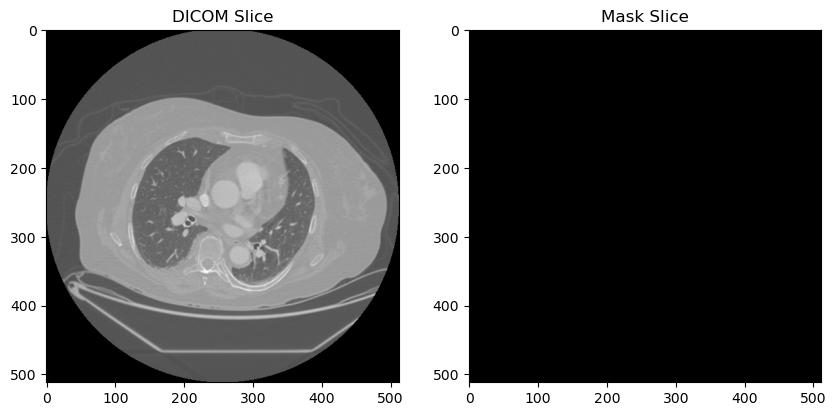


🔍 Mask filename: 92_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\92_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0092\01-01-2000-NA-NA-18458\3001608.000000-NA-25501
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0092\01-01-2000-NA-NA-96337\3000774.000000-NA-03667


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 92


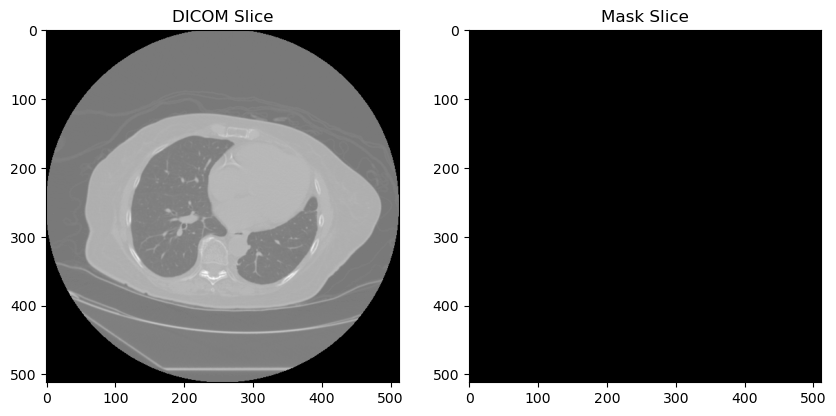


🔍 Mask filename: 93_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\93_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0093\01-01-2000-NA-NA-37140\3000688.000000-NA-62069


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 93


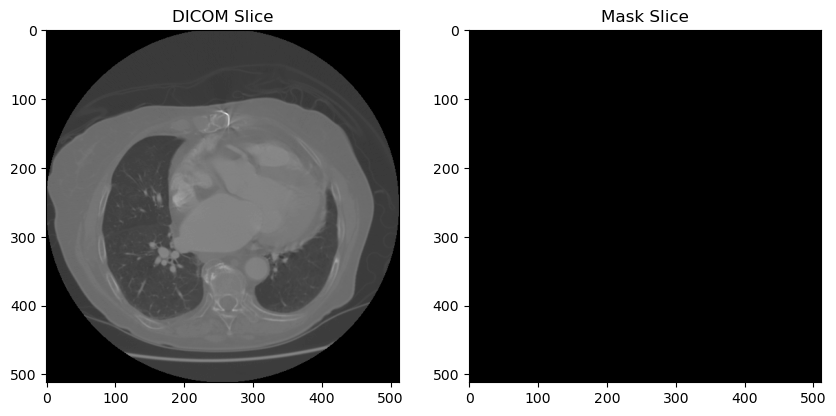

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0093\01-01-2000-NA-NA-80836\3000992.000000-NA-48388
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 94_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\94_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0094\01-01-2000-NA-NA-48640\5586.000000-W Chest PA-30232
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0094\01-01-2000-NA-NA-80662\5587.000000-Routine Chest  2.0  B70f-24839


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 94


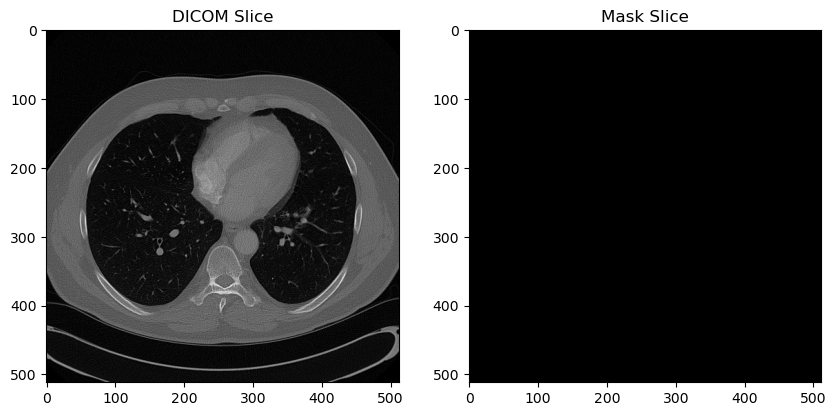


🔍 Mask filename: 95_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\95_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0095\01-01-2000-NA-NA-21977\5609.000000-W Chest PA-84162
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0095\01-01-2000-NA-NA-87188\5610.000000-ThorRoutine  2.0  B70f-15668


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 95


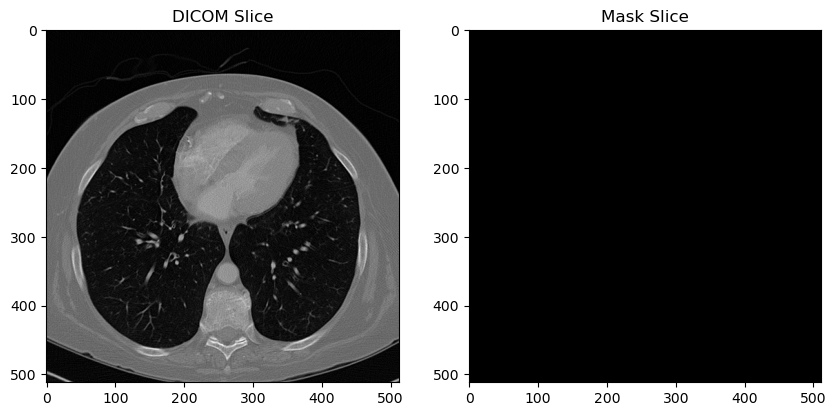


🔍 Mask filename: 96_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\96_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0096\01-01-2000-NA-NA-17180\3001573.000000-NA-65662
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0096\01-01-2000-NA-NA-27864\3000693.000000-NA-83845


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 96


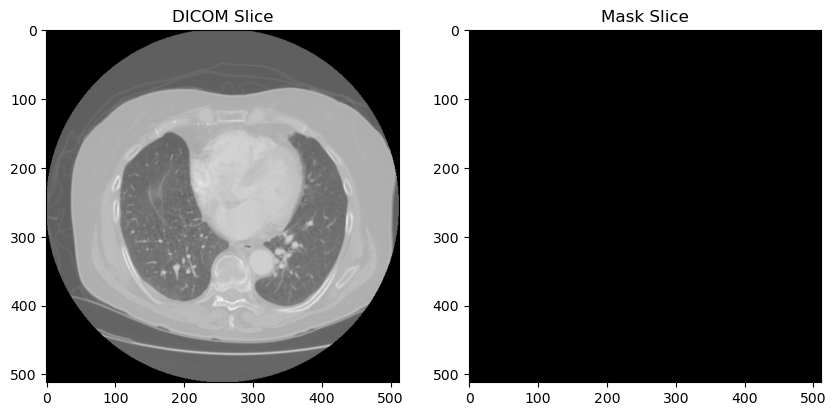


🔍 Mask filename: 97_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\97_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0097\01-01-2000-NA-NA-06388\3001606.000000-NA-05167
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0097\01-01-2000-NA-NA-69162\3000738.000000-NA-35891


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 97


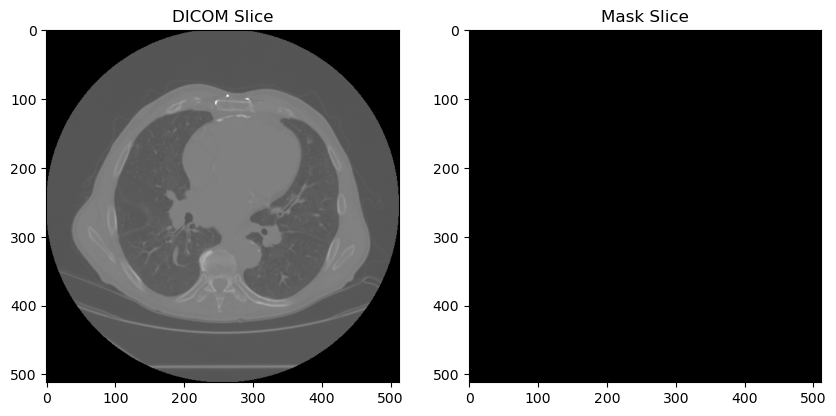


🔍 Mask filename: 98_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\98_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0098\01-01-2000-NA-NA-49269\3099.000000-NA-74211
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0098\01-01-2000-NA-NA-49269\3099.000000-NA-74211 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2140, 1760, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1760, 2140, 1]

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0098\01-01-2000-NA-NA-97960\3094.000000-ThoraxRoutine  3.0  B31s-45271


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 98


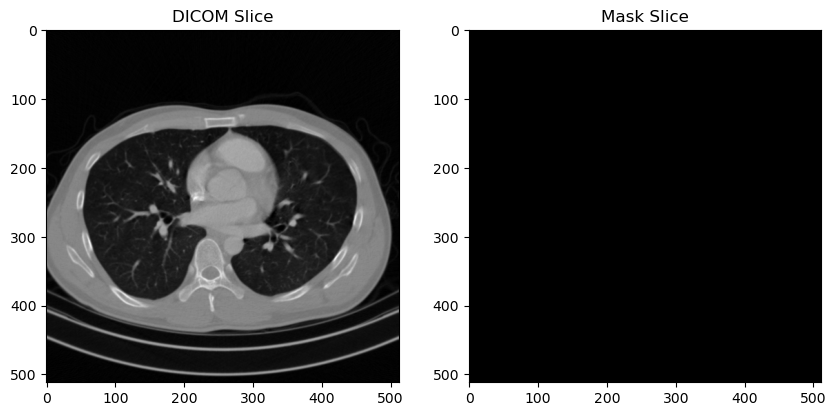


🔍 Mask filename: 99_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\99_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0099\01-01-2000-NA-NA-16145\3000655.000000-NA-53237


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 99


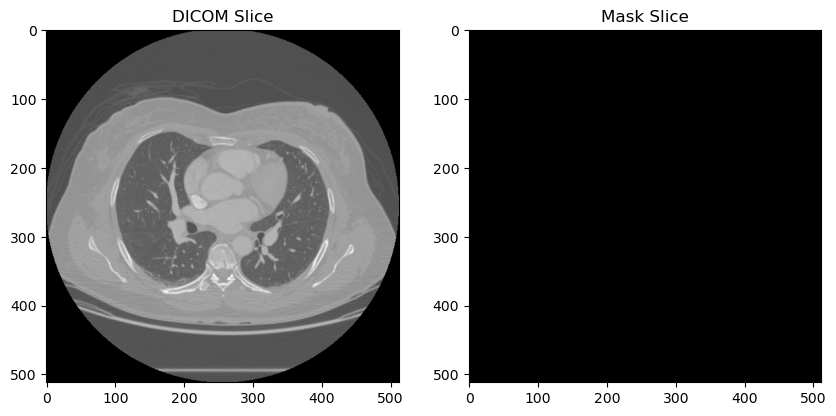

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0099\01-01-2000-NA-NA-39142\3000989.000000-NA-84905
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 101_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\101_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0101\01-01-2000-NA-NA-23891\3197.000000-W Chest PA-63200
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0101\01-01-2000-NA-NA-57752\3192.000000-ThoraxRoutine  3.0  B31s-17327


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 101


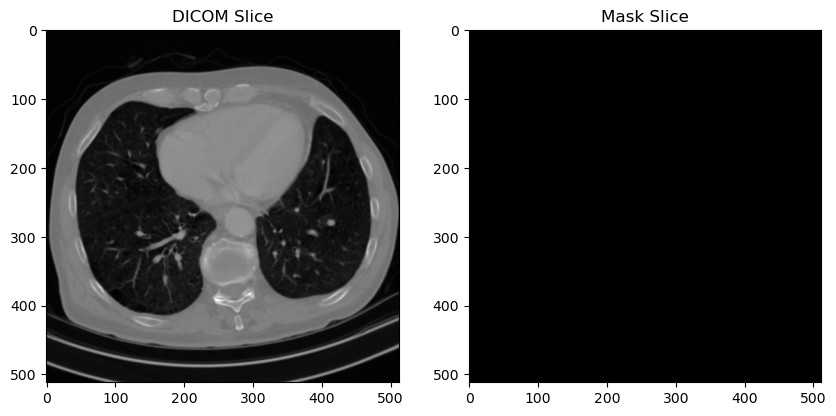


🔍 Mask filename: 102_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\102_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0102\01-01-2000-NA-NA-59212\3000991.000000-NA-60907
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0102\01-01-2000-NA-NA-76051\3000670.000000-NA-70157


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 102


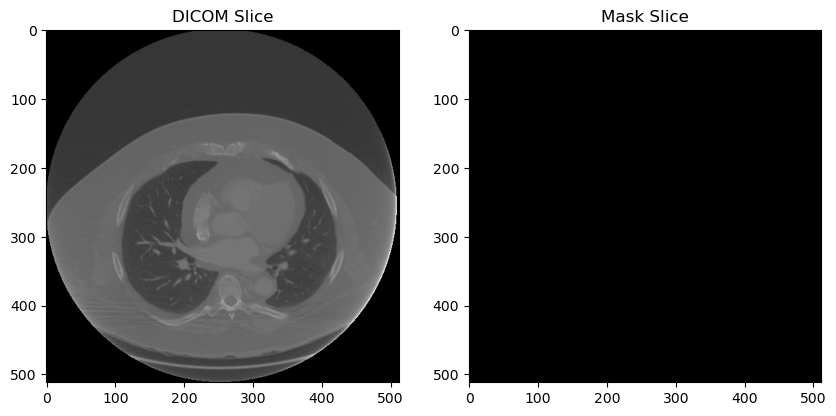


🔍 Mask filename: 103_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\103_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0103\01-01-2000-NA-NA-57835\5518.000000-NA-74407
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0103\01-01-2000-NA-NA-84710\5519.000000-ChestRoutine  3.0  B31f-39568


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 103


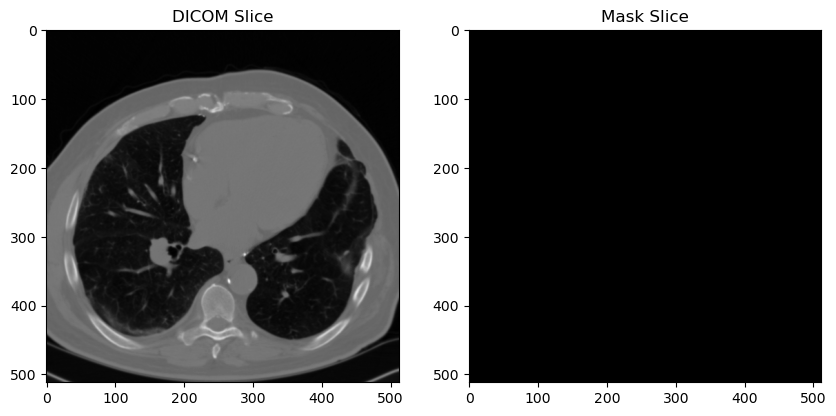


🔍 Mask filename: 104_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\104_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0104\01-01-2000-NA-NA-06046\5596.000000-NA-86789
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0104\01-01-2000-NA-NA-16722\5597.000000-NA-08531


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 104


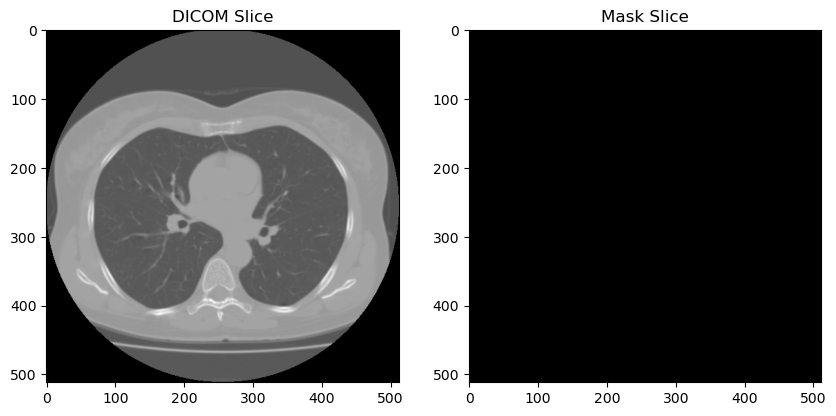


🔍 Mask filename: 105_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\105_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0105\01-01-2000-NA-NA-23262\3000665.000000-NA-78952


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 105


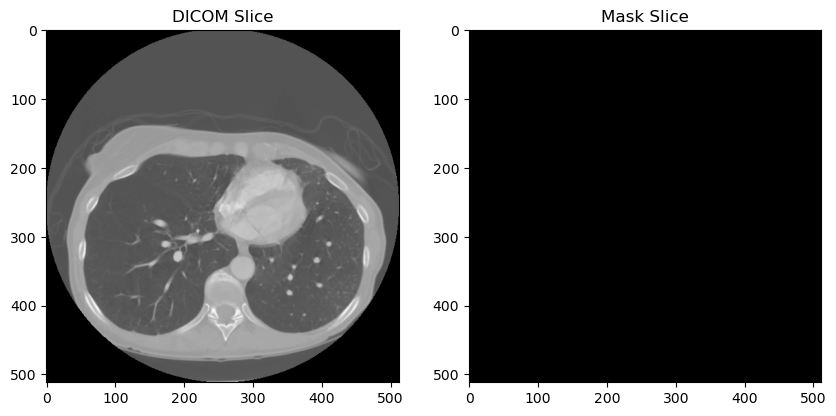

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0105\01-01-2000-NA-NA-54838\3001601.000000-NA-76030
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 106_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\106_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0106\01-01-2000-NA-NA-34664\3110.000000-W Chest PA-91999
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0106\01-01-2000-NA-NA-50782\3115.000000-NA-20243


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 106


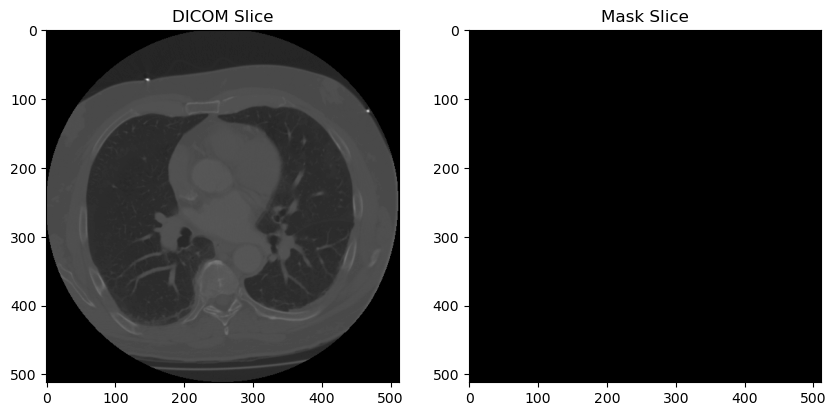


🔍 Mask filename: 107_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\107_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0107\01-01-2000-NA-NA-91396\5591.000000-NA-44791


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 107


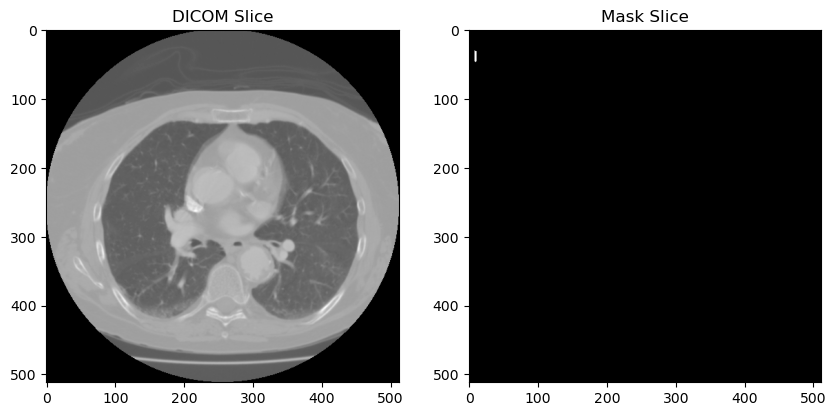

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0107\01-01-2000-NA-NA-94897\5590.000000-W Chest PA-65912
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 108_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\108_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0108\01-01-2000-NA-NA-23094\3000699.000000-NA-84679


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 108


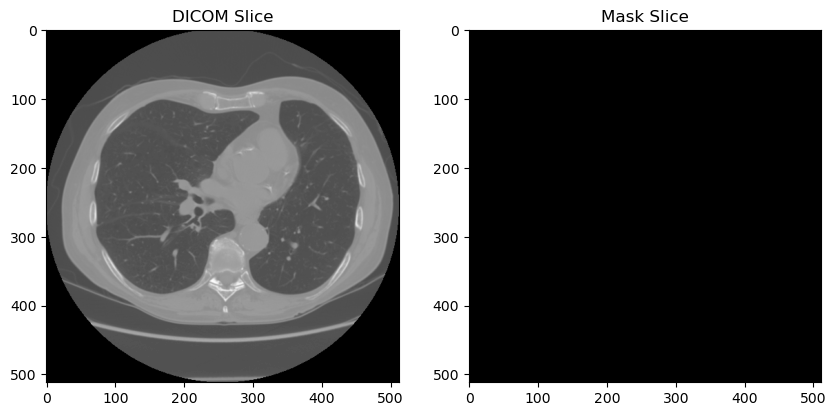

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0108\01-01-2000-NA-NA-73701\3001056.000000-NA-24001
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0108\01-01-2000-NA-NA-73701\3001056.000000-NA-24001 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 109_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\109_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0109\01-01-2000-NA-NA-06266\3000994.000000-NA-22868
⚠️ Unusually 

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 109


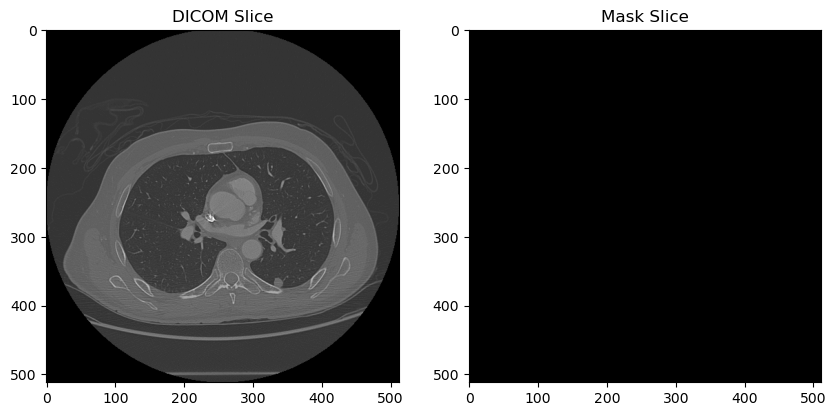


🔍 Mask filename: 110_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\110_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0110\01-01-2000-NA-NA-26515\3309.000000-ThoraxRoutine  3.0  B31f-73912


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 110


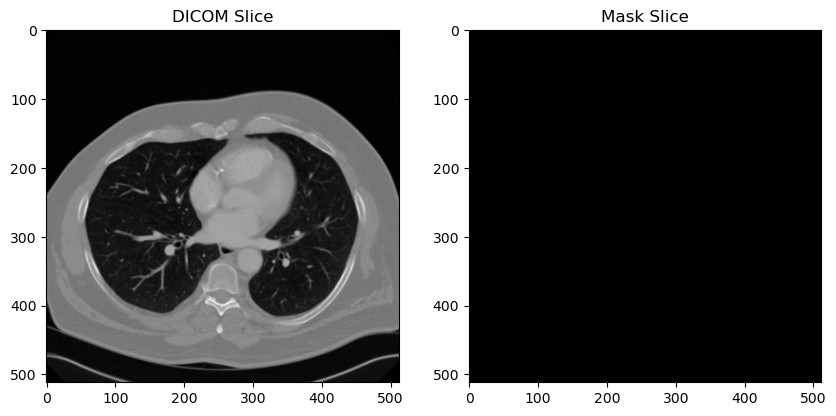

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0110\01-01-2000-NA-NA-44045\3308.000000-W Chest PA-08863
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 111_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\111_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0111\01-01-2000-NA-NA-02086\3000705.000000-NA-92959


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 111


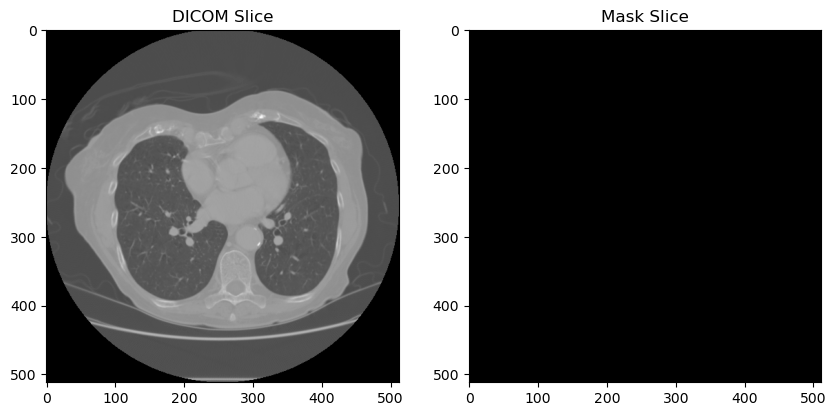

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0111\01-01-2000-NA-NA-66766\3001582.000000-NA-18239
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 112_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\112_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0112\01-01-2000-NA-NA-30946\3001599.000000-NA-75345
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0112\01-01-2000-NA-NA-30946\3001599.000000-NA-75345 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageSeriesReader.hxx:355:
ITK ERROR: ImageSeriesReader(000001679C6D2B90): Size mismatch! The size of  C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0112\01-01-2000-NA-NA-30946\3001599.000000-NA-75345/1-4.dcm is [2022, 2022, 1] and does not match the required size [1736

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 112


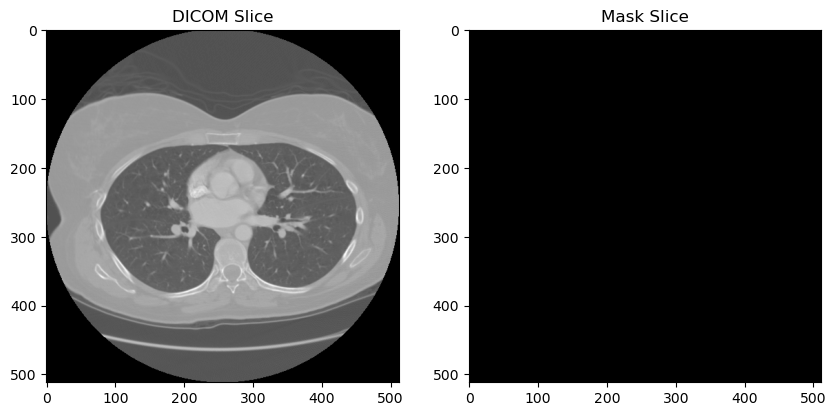


🔍 Mask filename: 113_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\113_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0113\01-01-2000-NA-NA-43730\3001571.000000-NA-77826
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0113\01-01-2000-NA-NA-92194\3000691.000000-NA-63327


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 113


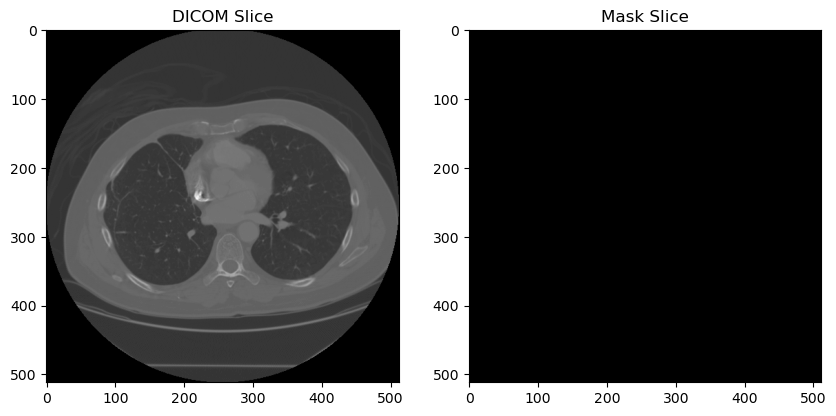


🔍 Mask filename: 114_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\114_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0114\01-01-2000-NA-NA-13309\3000984.000000-NA-57562
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0114\01-01-2000-NA-NA-97315\3000644.000000-NA-11228


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 114


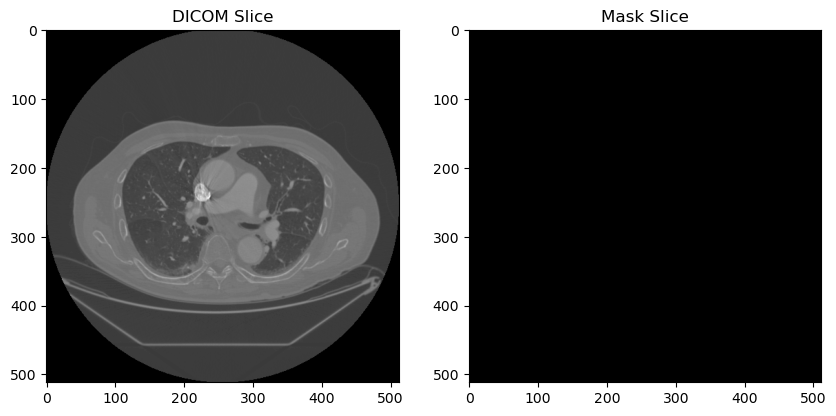


🔍 Mask filename: 115_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\115_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0115\01-01-2000-NA-NA-06680\3236.000000-NA-37997


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 115


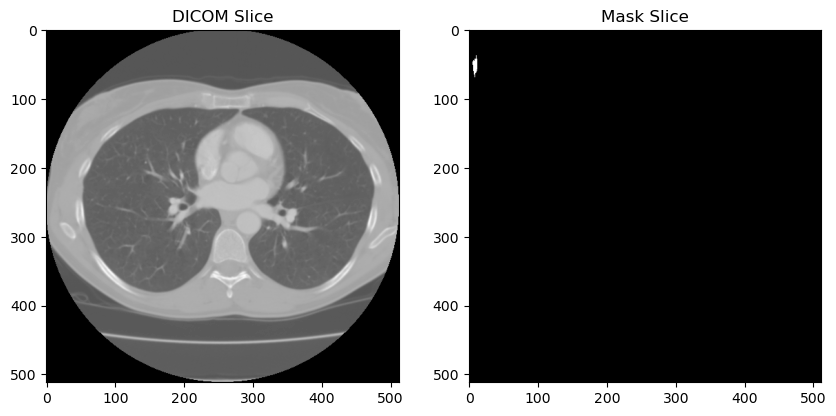

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0115\01-01-2000-NA-NA-79031\3240.000000-NA-01933
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 116_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\116_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0116\01-01-2000-NA-NA-34322\3000700.000000-NA-19196


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 116


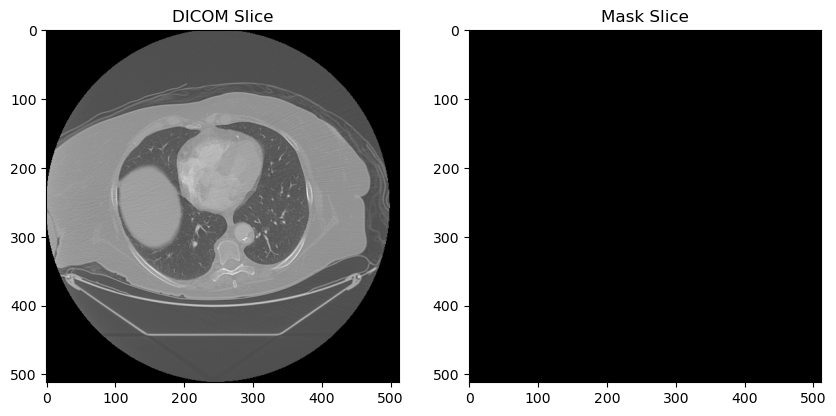

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0116\01-01-2000-NA-NA-92107\3001577.000000-NA-17640
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 117_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\117_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0117\01-01-2000-NA-NA-09107\3084.000000-NA-91206


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 117


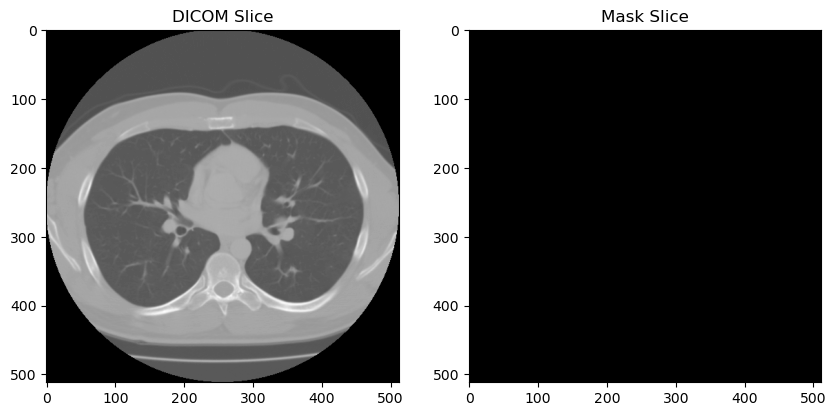

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0117\01-01-2000-NA-NA-82328\3087.000000-W Chest PA-28575
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 118_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\118_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0118\01-01-2000-NA-CHEST PA - LAT-79139\33297.000000-CHEST PA - LAT-94758
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0118\01-01-2000-NA-CT CHEST W CONT-82336\4.000000-Recon 3 CHEST-57528


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 118


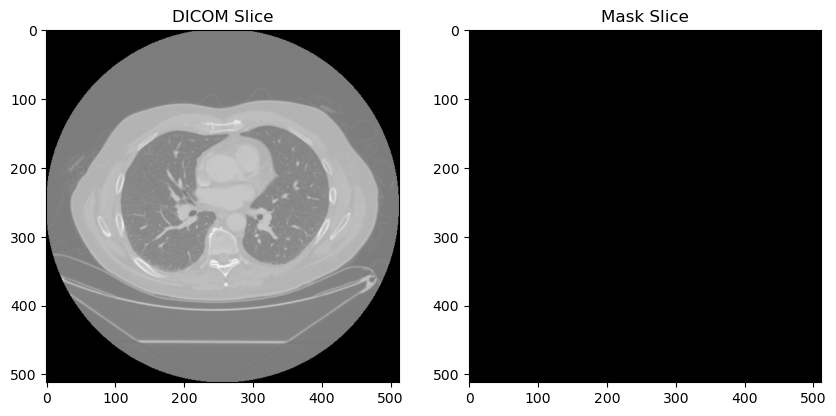


🔍 Mask filename: 119_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\119_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0119\01-01-2000-NA-NA-54647\5608.000000-ThorRoutine  2.0  B70f-82299


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 119


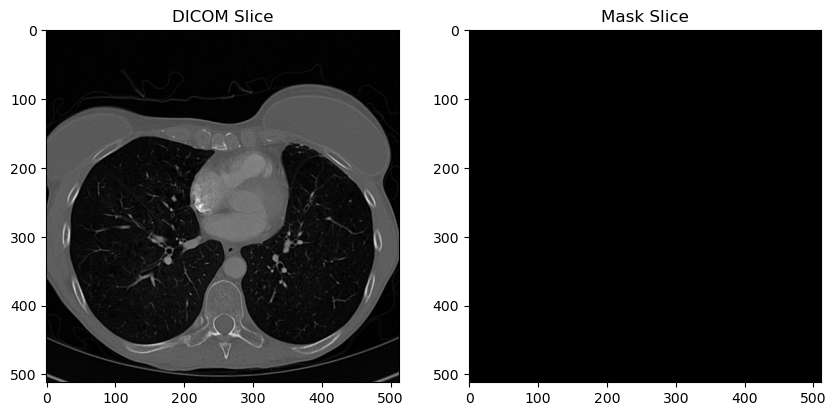

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0119\01-01-2000-NA-NA-83412\5607.000000-W Chest PA-97571
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 120_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\120_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0120\01-01-2000-NA-NA-04772\3219.000000-W Chest PA-18213
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0120\01-01-2000-NA-NA-71173\3221.000000-NA-29969


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 120


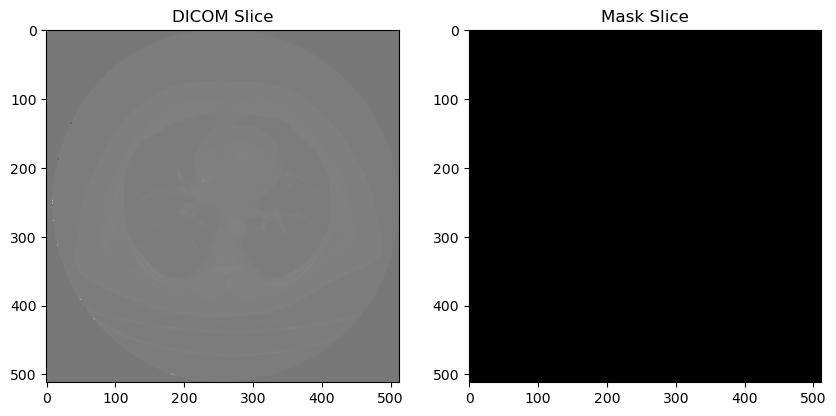


🔍 Mask filename: 121_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\121_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0121\01-01-2000-NA-NA-41529\3000776.000000-NA-23312


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 121


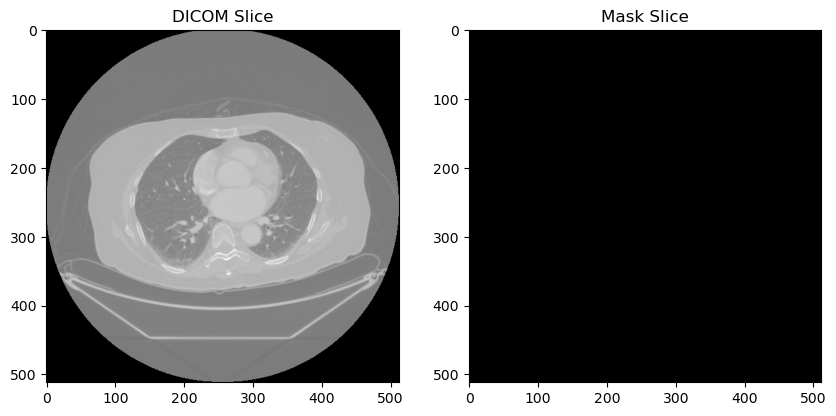

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0121\01-01-2000-NA-NA-60117\3001609.000000-NA-11649
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 122_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\122_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0122\01-01-2000-NA-NA-66616\3000695.000000-NA-41492


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 122


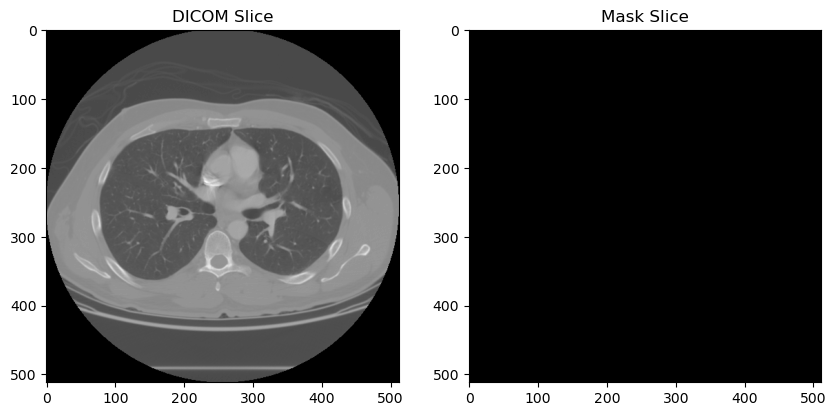

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0122\01-01-2000-NA-NA-86810\3001575.000000-NA-07933
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0122\01-01-2000-NA-NA-86810\3001575.000000-NA-07933 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1916, 2022, 1]


🔍 Mask filename: 123_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\123_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0123\01-01-2000-NA-NA-90864\3000986.000000-NA-78955
⚠️ Unusually 

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 123


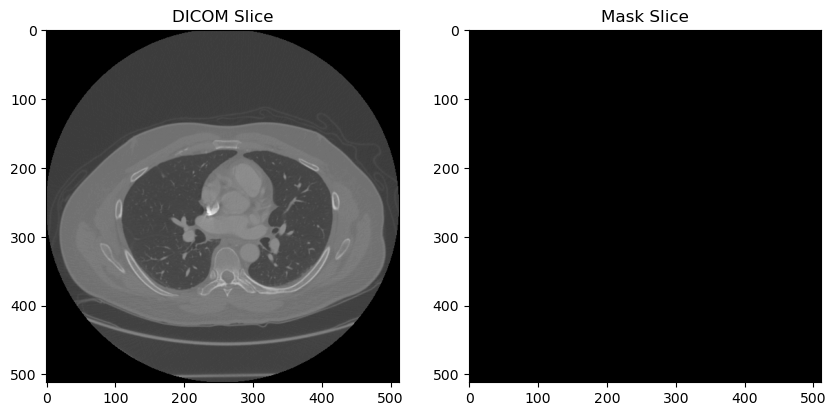


🔍 Mask filename: 124_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\124_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0124\01-01-2000-NA-CAP-93667\3.000000-Recon 2 C-A-P-11437


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 124


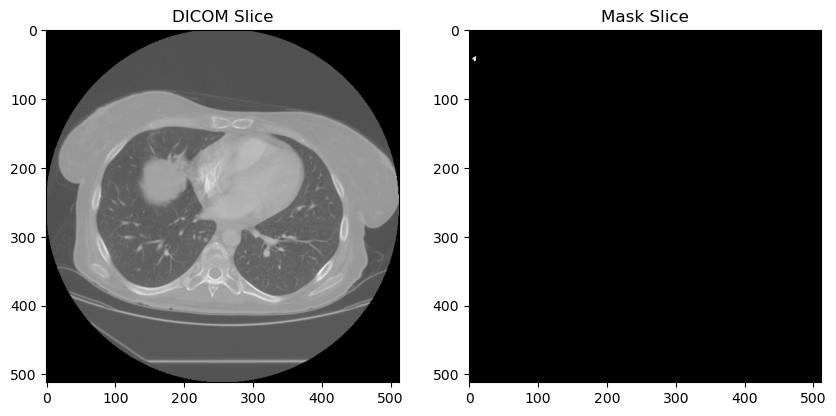

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0124\01-01-2000-NA-CHEST PA  LATERAL-83635\28247.000000-CHEST PA  LATERAL-33321
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0124\01-01-2000-NA-CHEST PA  LATERAL-83635\28247.000000-CHEST PA  LATERAL-33321 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 125_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\125_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0125\01-0

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 125


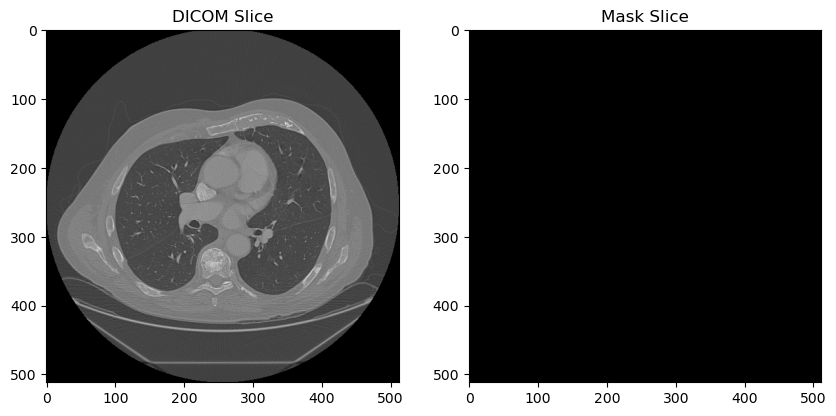


🔍 Mask filename: 126_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\126_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0126\01-01-2000-NA-NA-42927\3000982.000000-NA-30443
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0126\01-01-2000-NA-NA-94320\3000639.000000-NA-58130


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 126


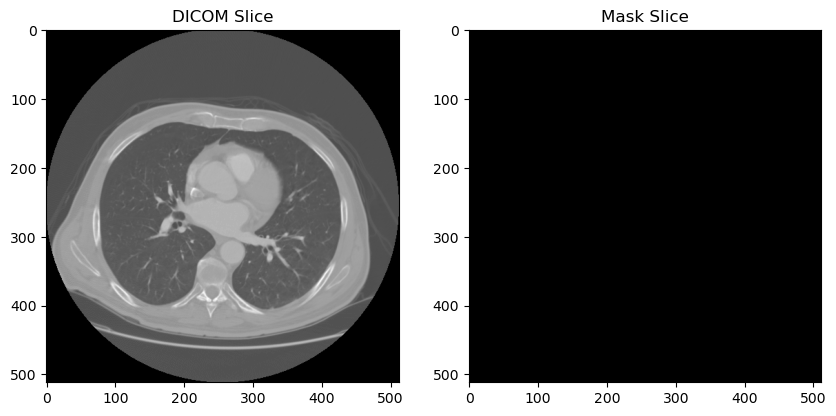


🔍 Mask filename: 127_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\127_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0127\01-01-2000-NA-NA-00442\3318.000000-ChestRoutine  3.0  B31f-89892


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 127


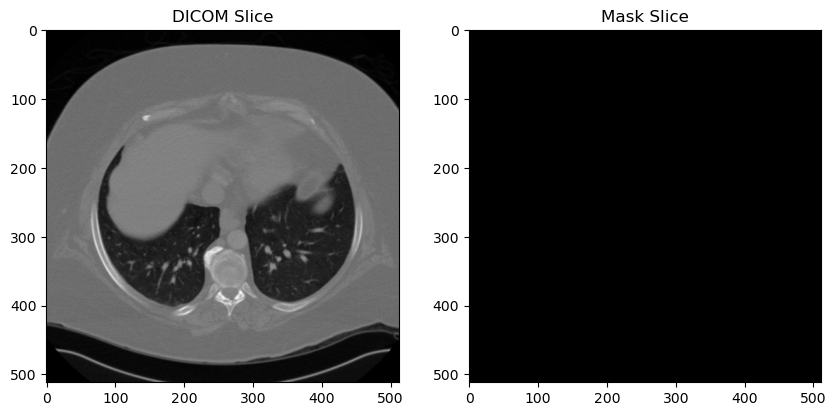

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0127\01-01-2000-NA-NA-81729\3317.000000-W Chest PA-84836
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 128_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\128_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0128\01-01-2000-NA-NA-03064\3001607.000000-NA-19595
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0128\01-01-2000-NA-NA-25676\3000740.000000-NA-19144


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 128


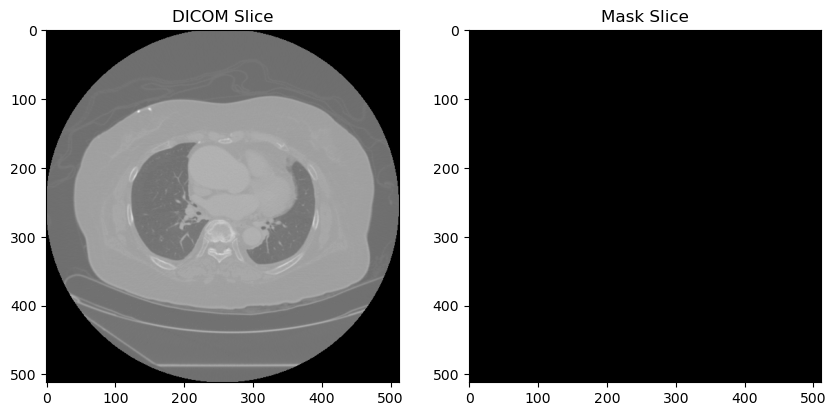


🔍 Mask filename: 129_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\129_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0129\01-01-2000-NA-CHEST PA  LATERAL-33224\25745.000000-CHEST PA  LATERAL-48483
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0129\01-01-2000-NA-CT ANGIO CHEST WWO C-30279\2.000000-BOTTOM TO TOP-12518


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 129


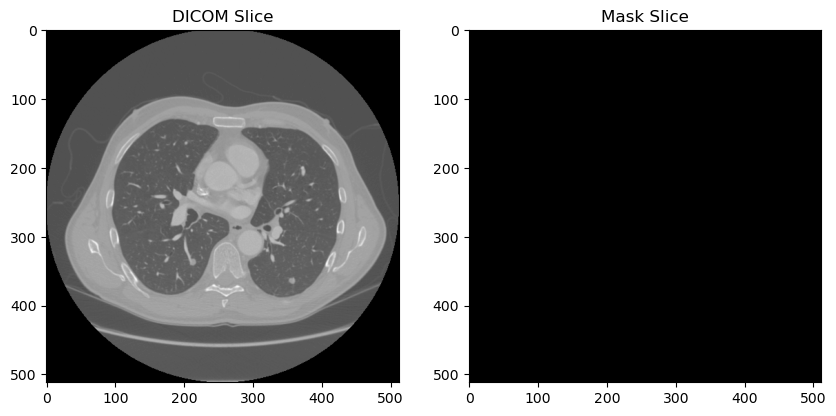


🔍 Mask filename: 130_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\130_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0130\01-01-2000-NA-NA-34844\5582.000000-ThorRoutine  2.0  B70f-24817


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 130


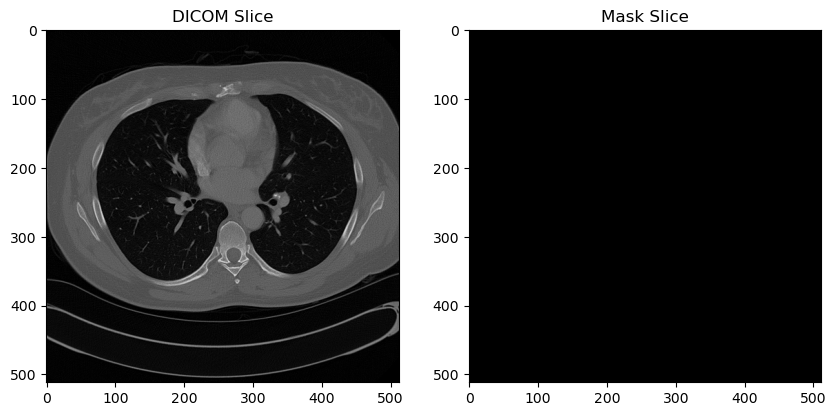

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0130\01-01-2000-NA-NA-81511\5581.000000-NA-02880
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 131_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\131_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0131\01-01-2000-NA-NA-20316\3000694.000000-NA-09852


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 131


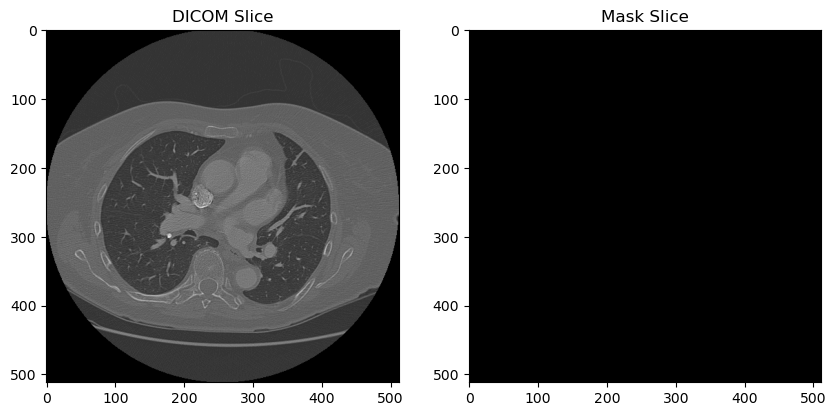

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0131\01-01-2000-NA-NA-93333\3001574.000000-NA-66716
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 132_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\132_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0132\01-01-2000-NA-NA-29678\3163.000000-ChestRoutine  3.0  B31f-22057


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 132


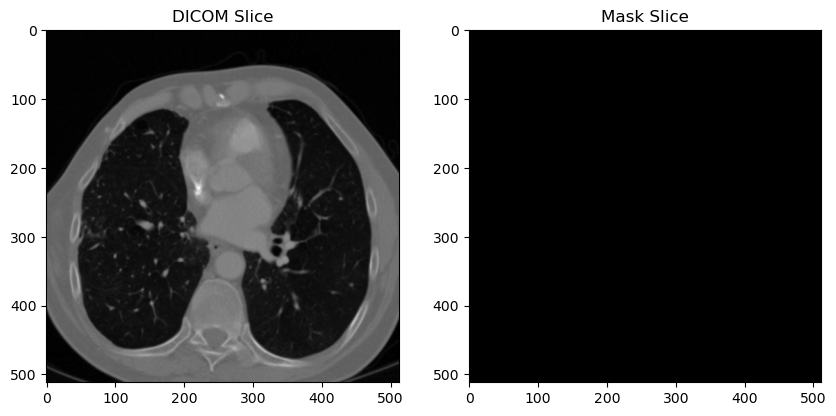

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0132\01-01-2000-NA-NA-34723\3172.000000-W Chest PA-83099
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0132\01-01-2000-NA-NA-67346\5418.000000-ThorRoutine  3.0  B31f-62989


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 132


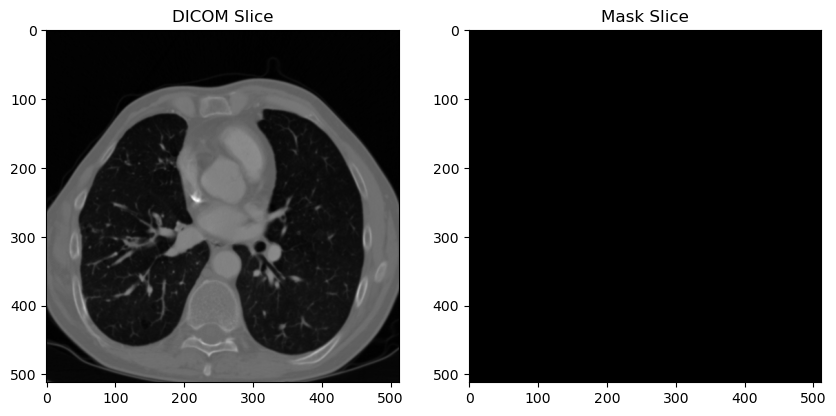


🔍 Mask filename: 133_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\133_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0133\01-01-2000-NA-NA-58320\3000993.000000-NA-96632
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0133\01-01-2000-NA-NA-75083\3000689.000000-NA-47209


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 133


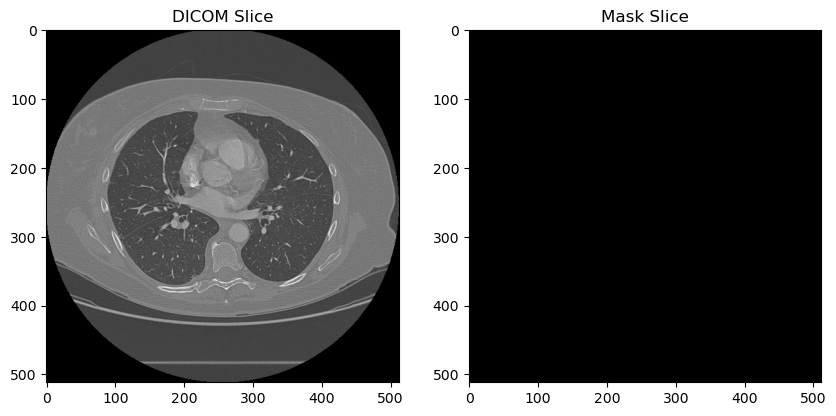


🔍 Mask filename: 134_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\134_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0134\01-01-2000-NA-NA-04239\5508.000000-NA-62582


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 134


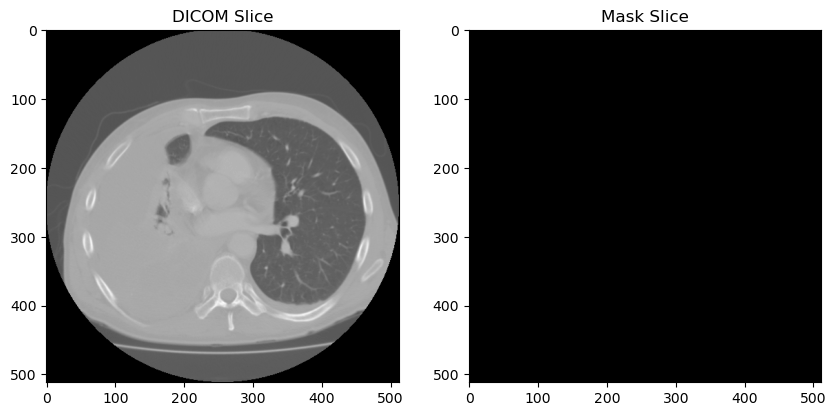

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0134\01-01-2000-NA-NA-38369\5507.000000-W Chest PA-73281
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 135_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\135_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0135\01-01-2000-NA-CHEST PA  LATERAL-28131\22553.000000-CHEST PA  LATERAL-07241
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0135\01-01-2000-NA-CT THORAX WCONTRAST-77417\3.000000-Recon 2 C-A-P-38704


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 135


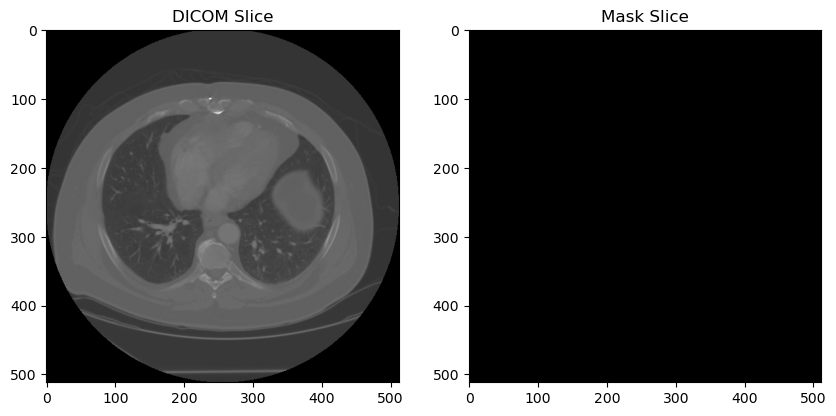


🔍 Mask filename: 136_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\136_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0136\01-01-2000-NA-NA-94990\3108.000000-W Chest PA-62296
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0136\01-01-2000-NA-NA-99869\3133.000000-ChestRoutine  3.0  B31f-06739


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 136


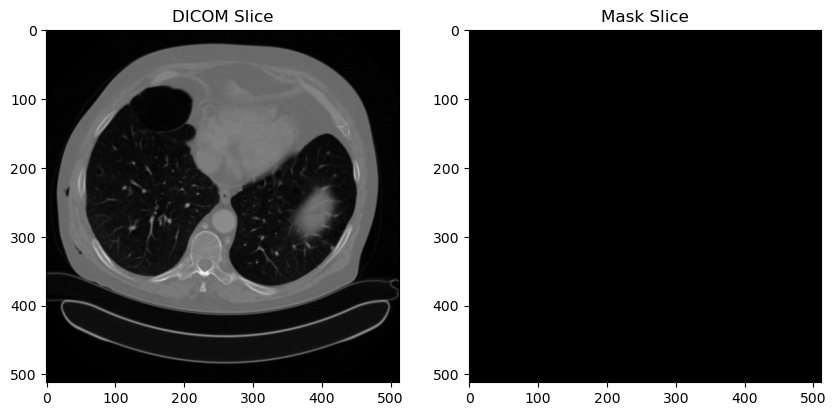


🔍 Mask filename: 137_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\137_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0137\01-01-2000-NA-CHEST PA  LATERAL-90589\19901.000000-CHEST PA  LATERAL-36018
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0137\01-01-2000-NA-CT THORAX WCONTRAST-20553\3.000000-Recon 2 CHEST-96610


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 137


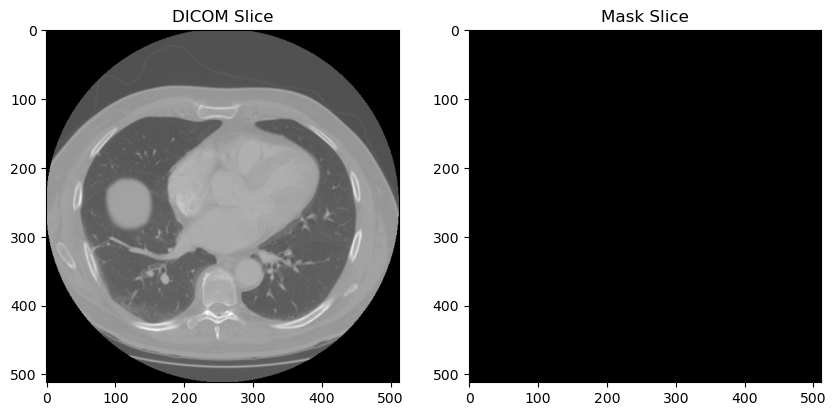


🔍 Mask filename: 138_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\138_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0138\01-01-2000-NA-CHEST PA - LAT-64404\14605.000000-Chest pa-36775
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0138\01-01-2000-NA-CT CHEST W CONT-37148\102.000000-CT CHEST 5 X 5-89059


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 138


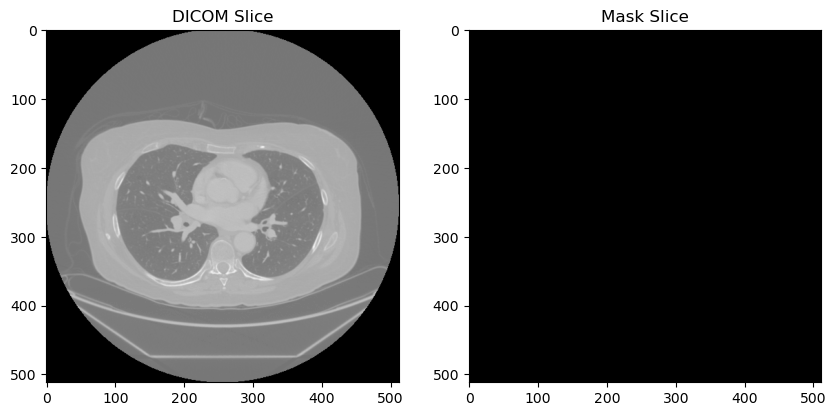


🔍 Mask filename: 139_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\139_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0139\01-01-2000-NA-NA-40012\3000692.000000-NA-24156


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 139


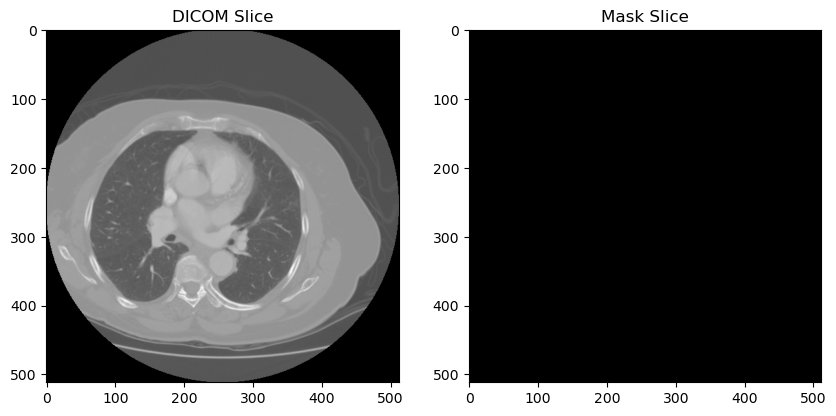

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0139\01-01-2000-NA-NA-87111\3001572.000000-NA-42076
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0139\01-01-2000-NA-NA-87111\3001572.000000-NA-42076 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]


🔍 Mask filename: 140_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\140_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0140\01-01-2000-NA-NA-14219\5583.000000-W Chest PA-46403
⚠️ Unusu

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 140


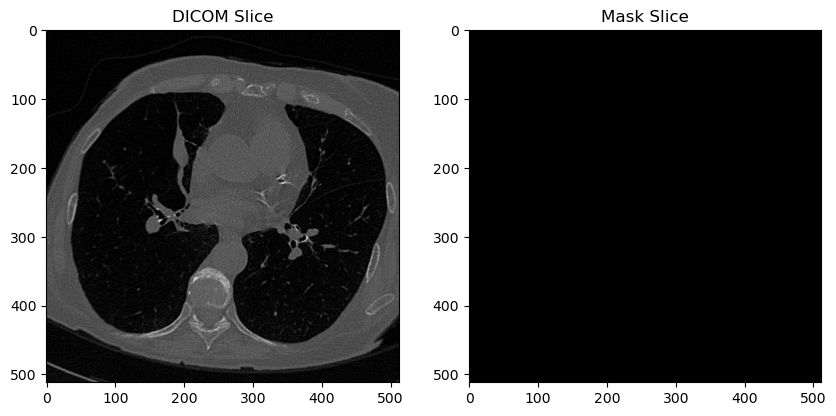


🔍 Mask filename: 141_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\141_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0141\01-01-2000-NA-NA-68360\5606.000000-ThorRoutine  2.0  B70f-83786


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 141


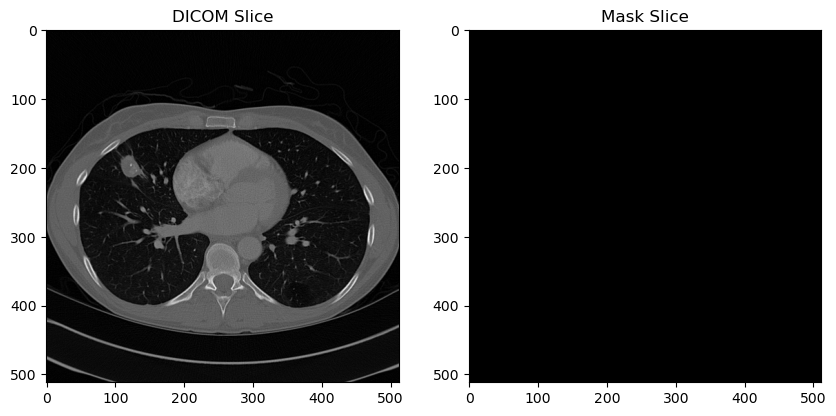

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0141\01-01-2000-NA-NA-85720\5605.000000-W Chest PA-86448
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 142_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\142_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0142\01-01-2000-NA-NA-58853\5593.000000-ThorRoutine  2.0  B70f-43044


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 142


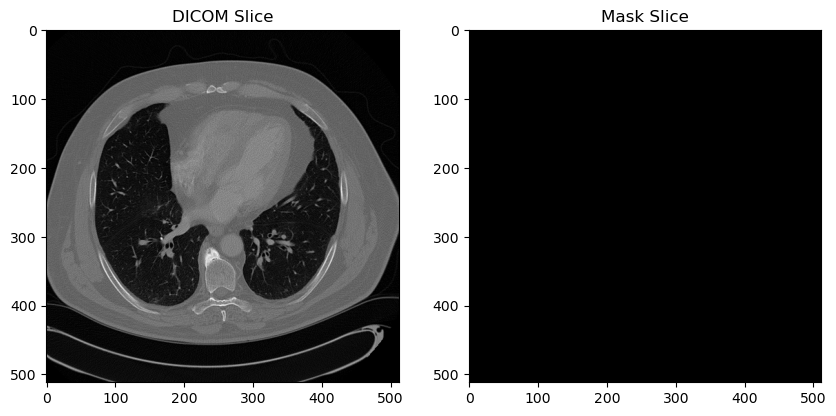

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0142\01-01-2000-NA-NA-63790\5592.000000-W Chest PA-21412
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 144_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\144_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0144\01-01-2000-NA-NA-61308\3000703.000000-NA-75826


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 144


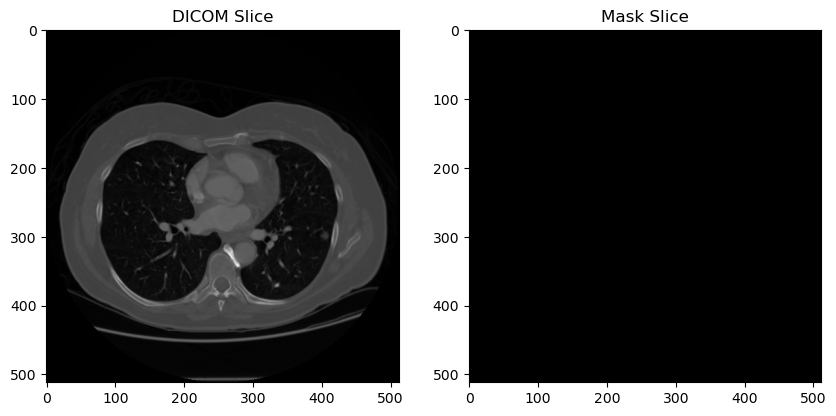

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0144\01-01-2000-NA-NA-72023\3001580.000000-NA-00978
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 145_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\145_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0145\01-01-2000-NA-NA-44241\3000668.000000-NA-22488


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 145


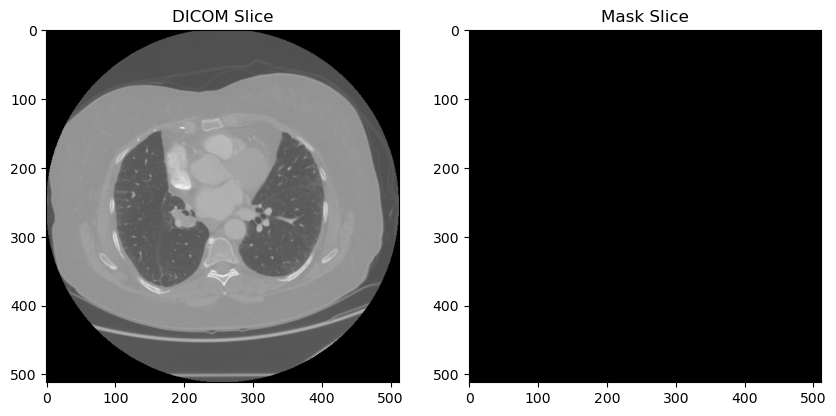

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0145\01-01-2000-NA-NA-60671\3001603.000000-NA-88945
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 146_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\146_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0146\01-01-2000-NA-NA-37649\3000653.000000-NA-67579


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 146


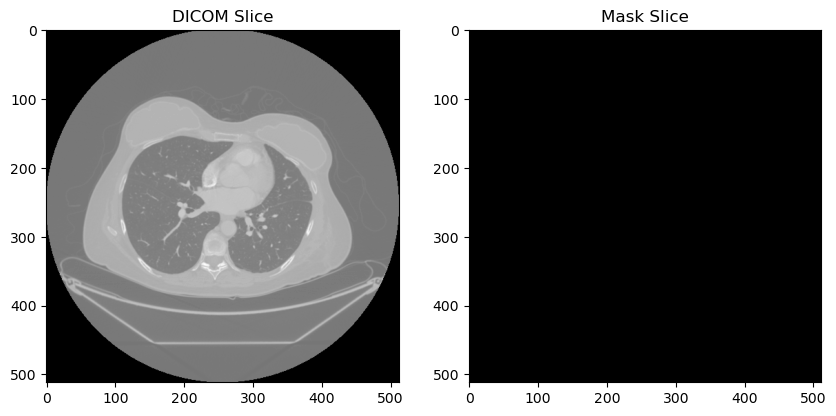

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0146\01-01-2000-NA-NA-47237\3000988.000000-NA-18356
⚠️ Unusually large DICOM volume detected, skipping.

🔍 Mask filename: 147_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\147_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0147\01-01-2000-NA-NA-32032\3312.000000-W Chest PA-55516
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0147\01-01-2000-NA-NA-38716\3313.000000-NA-45208


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 147


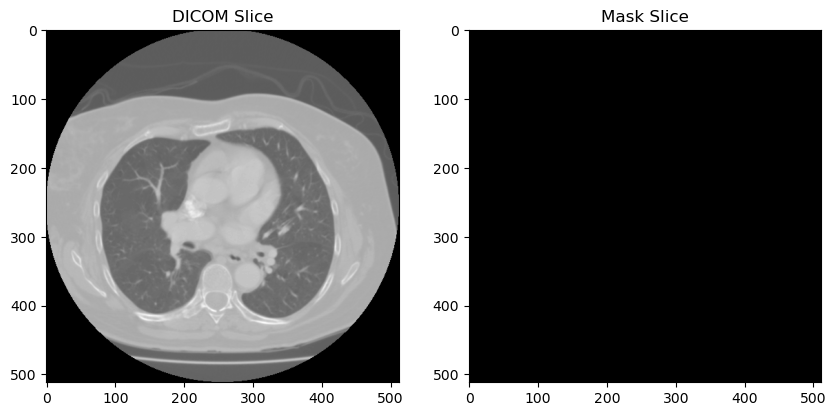


🔍 Mask filename: 148_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\148_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0148\01-01-2000-NA-CHEST PA  LATERAL-60353\8806.000000-CHEST PA  LATERAL-56967
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0148\01-01-2000-NA-CT THORAX WCONTRAST-41427\3.000000-Recon 2 CHEST-05032


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 148


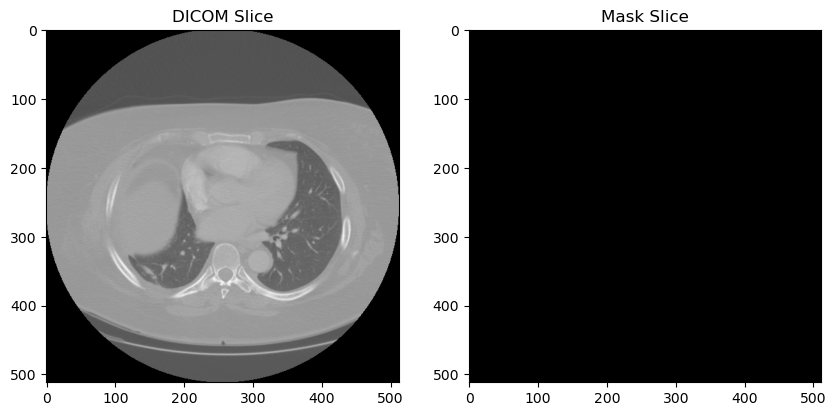


🔍 Mask filename: 149_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\149_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0149\01-01-2000-NA-CHEST PA  LATERAL-22999\9569.000000-CHEST PA  LATERAL-14586
❌ Could not process C:/Users/user/Desktop/PI_project/images/LIDC-IDRI\LIDC-IDRI-0149\01-01-2000-NA-CHEST PA  LATERAL-22999\9569.000000-CHEST PA  LATERAL-14586 due to error:
Exception thrown in SimpleITK ImageSeriesReader_Execute: D:\a\SimpleITK\SimpleITK\bld\ITK-prefix\include\ITK-5.4\itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (000000104B5E88A0)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [2022, 2022, 1]
StreamableRegion region: ImageRegion (000000104B5E8910)
  Dimension: 3
  Index: [0, 0, 0]
  Size: [1736, 2022, 1]

📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0149\01-01-

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


✅ Features extracted for Nodule 149


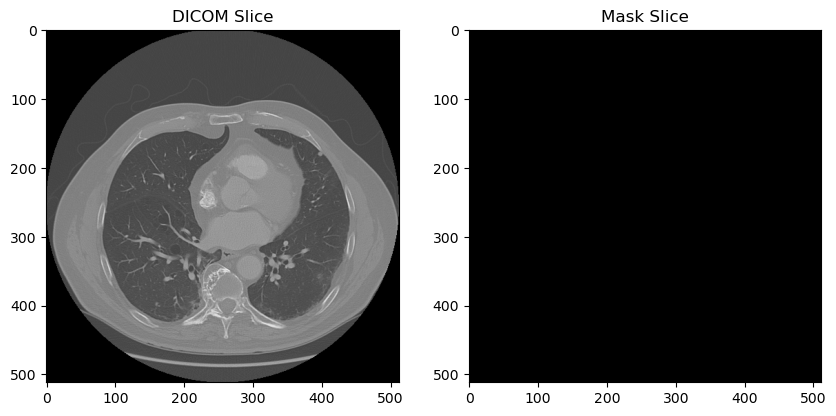


🔍 Mask filename: 150_cmask.npy
🔍 Looking for mask in: C:\Users\user\Desktop\PI_project\deeplung_features\150_cmask.npy
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0150\01-01-2000-NA-NA-42623\3189.000000-W Chest PA-93281
⚠️ Unusually large DICOM volume detected, skipping.
📦 Reading DICOM series from: C:\Users\user\Desktop\PI_project\images\LIDC-IDRI\LIDC-IDRI-0150\01-01-2000-NA-NA-49358\3185.000000-NA-66614


KeyboardInterrupt: 

In [196]:
import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
from radiomics import featureextractor
import matplotlib.pyplot as plt

# Paths
input_directory = "C:/Users/user/Desktop/PI_project/images/LIDC-IDRI"
params_file = "C:/Users/user/Desktop/PI_project/radiomics_config/Params3D.yaml"
mask_directory = "C:/Users/user/Desktop/PI_project/deeplung_features"
output_directory = "C:/Users/user/Desktop/PI_project"

# Initialize Extractor
extractor = featureextractor.RadiomicsFeatureExtractor(params_file)

# Storage for extracted features
dic_list = []

# Track processed nodules to avoid duplicates
processed_nodules = set()

# Traverse LIDC-IDRI Folder
for patient_id in sorted(os.listdir(input_directory)):
    patient_path = os.path.join(input_directory, patient_id)
    if not os.path.isdir(patient_path):
        continue

    # Construct expected nodule mask filename
    nodule_number = patient_id.split('-')[-1].lstrip('0') or '0'
    mask_filename = f"{nodule_number}_cmask.npy"
    mask_path = os.path.join(mask_directory, mask_filename)

    print(f"\n🔍 Mask filename: {mask_filename}")
    print(f"🔍 Looking for mask in: {os.path.normpath(mask_path)}")

    if not os.path.exists(mask_path):
        print(f"❌ Mask not found for nodule {nodule_number}")
        continue
    if nodule_number in processed_nodules:
        print(f"⚠️ Skipping duplicate mask for nodule {nodule_number}")
        continue

    for study in os.listdir(patient_path):
        study_path = os.path.join(patient_path, study)
        for series in os.listdir(study_path):
            series_path = os.path.join(study_path, series)
            print(f"📦 Reading DICOM series from: {os.path.normpath(series_path)}")

            try:
                # Load DICOM Volume
                reader = sitk.ImageSeriesReader()
                dicom_names = reader.GetGDCMSeriesFileNames(series_path)
                if not dicom_names:
                    print("⚠️ No DICOM slices found.")
                    continue

                reader.SetFileNames(dicom_names)
                image_3d = reader.Execute()

                # Skip unusually large volumes (to avoid crashing on corrupted data)
                if image_3d.GetSize()[0] > 1024:
                    print(f"⚠️ Unusually large DICOM volume detected, skipping.")
                    continue

                # Load and Convert Mask
                mask_np = np.load(mask_path).astype(np.uint8)

                if mask_np.ndim == 2:
                    print(f"⚠️ 2D mask detected, converting to 3D by tiling across depth.")
                    mask_3d = np.stack([mask_np] * image_3d.GetSize()[2], axis=0)
                elif mask_np.ndim == 3 and mask_np.shape[0] > 0:
                    mask_3d = mask_np
                else:
                    print(f"❌ Invalid mask shape: {mask_np.shape}")
                    break

                if np.sum(mask_3d) == 0:
                    print(f"❌ Original mask is empty for nodule {nodule_number}")
                    break

                # Convert Mask to SimpleITK
                mask_sitk = sitk.GetImageFromArray(mask_3d)
                mask_sitk.SetOrigin(image_3d.GetOrigin())
                mask_sitk.SetSpacing(image_3d.GetSpacing())
                mask_sitk.SetDirection(image_3d.GetDirection())

                # Resample Mask to Align with Image
                resampler = sitk.ResampleImageFilter()
                resampler.SetReferenceImage(image_3d)
                resampler.SetInterpolator(sitk.sitkNearestNeighbor)
                resampler.SetTransform(sitk.Transform())
                mask_resampled = resampler.Execute(mask_sitk)

                # Final Check: Mask has labels after resampling
                if np.sum(sitk.GetArrayFromImage(mask_resampled)) == 0:
                    print(f"❌ Resampled mask for nodule {nodule_number} is empty")
                    break

                # Feature Extraction
                features = extractor.execute(image_3d, mask_resampled, label=1)
                features['PatientID'] = patient_id
                features['NoduleID'] = nodule_number
                dic_list.append(features)
                processed_nodules.add(nodule_number)
                print(f"✅ Features extracted for Nodule {nodule_number}")

                # Visualization of Middle Slice
                dicom_array = sitk.GetArrayFromImage(image_3d)
                mask_array = sitk.GetArrayFromImage(mask_resampled)

                if dicom_array.shape == mask_array.shape:
                    slice_idx = dicom_array.shape[0] // 2
                    plt.figure(figsize=(10, 5))
                    plt.subplot(1, 2, 1)
                    plt.imshow(dicom_array[slice_idx], cmap='gray')
                    plt.title("DICOM Slice")

                    plt.subplot(1, 2, 2)
                    plt.imshow(mask_array[slice_idx], cmap='gray')
                    plt.title("Mask Slice")
                    plt.show()
                else:
                    print(f"⚠️ Shape mismatch during visualization: {dicom_array.shape} vs {mask_array.shape}")

                break  # Stop after first good series

            except Exception as e:
                print(f"❌ Could not process {series_path} due to error:\n{e}")
                continue

# Save Extracted Features
features_df = pd.DataFrame(dic_list)
output_path = os.path.join(output_directory, 'features_radiomics_3d.csv')
features_df.to_csv(output_path, index=False)
print(f"\n✅ Radiomic features saved to: {output_path}")
